In [ ]:
# Sem "==" de propósito: primeiro registramos as versões que o Colab instalou (célula 1).
# No notebook final vamos "congelar" com pip install pacote==versão, para reprodutibilidade.
# Se der erro de numpy/binários depois da instalação: Ambiente de execução > Reiniciar sessão.
!pip -q install yfinance==0.2.66 prophet==1.4.0 statsmodels==0.15.0 arch==8.0.0 scipy==1.16.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 17.8 MB/s eta 0:00:00


Célula 1: configuração global, seed e versões

In [2]:
import sys, random, hashlib, warnings
import numpy as np, pandas as pd, scipy
import matplotlib, matplotlib.pyplot as plt
import statsmodels, yfinance, prophet, arch

# ===================== CONFIGURAÇÃO GLOBAL =====================
# Único lugar onde estes valores são definidos. Todo o notebook lê daqui,
# o que evita a inconsistência treino/teste do tutorial original (falha 7).
SEED       = 42
TICKER     = "BTC-USD"
START      = "2017-01-01"
END_EXCL   = "2026-01-01"  # yfinance trata 'end' como EXCLUSIVO -> última data = 2025-12-31
H_TEST     = 365           # nº de observações FINAIS reservadas para teste (= horizonte da origem única)
# Validação de origem móvel (Etapa 5): valores definidos aqui para não divergirem entre células.
# REGRA: qualquer escolha de hiperparâmetros por validação cruzada roda SOMENTE dentro de `train`.
# O teste (2025) NUNCA entra na CV. Ele é visto na Etapa 4 (replicação do desenho do tutorial) e na Etapa 6 (avaliação
# formal), e a Etapa 7 (diagnóstico dos intervalos) o vê de novo: mais de uma vez, e isso deve ser declarado.
# CV_HORIZON (30 d) e H_TEST (365 d) são tarefas diferentes:
# reportá-los em tabelas separadas, nunca misturados.
CV_INITIAL = 1460          # tamanho mínimo do primeiro treino (dias)
CV_HORIZON = 30            # horizonte de cada previsão (dias)
CV_STEP    = 30            # deslocamento entre origens sucessivas (dias)
CV_MAX_ORIGENS = None      # None = todas as origens; use um inteiro pequeno (ex.: 3) só para TESTAR o código
# ETAPA 6 (teste de 2025): lista de modelos FIXADA ANTES de rodar a Etapa 6. Nada será acrescentado, removido ou
# reajustado depois de ver o teste. O candidato do Prophet vem da regra da CV (Etapa 5): menor RMSE em log, só no treino.
# A Etapa 5 confere (assert) que a regra da CV e este valor coincidem; se não coincidirem, a Etapa 6 NÃO roda.
MODELOS_TESTE = ["naive", "drift_log", "drift_nivel", "naive_sazonal_7d",           # benchmarks
                 "prophet_nivel_default", "prophet_log_default",                  # Prophet com defaults (nível e log)
                 "prophet_log_cps0.5"]                                            # candidato da CV
CANDIDATO_PROPHET = "prophet_log_cps0.5"
N_PERM     = 200           # nº de permutações da Etapa 3 (controle da sazonalidade); reduza para ~50 se demorar
# Análise
MAX_LAGS   = 40            # nº de defasagens exibidas nas ACF/PACF
ALPHA      = 0.05          # nível de significância dos testes
# ================================================================

# Seed fixa. ATENÇÃO: a seed global só garante repetibilidade se a ORDEM de execução das células for
# idêntica; por isso reseed() deve ser chamada imediatamente antes de CADA operação aleatória
# (ex.: antes de cada predict do Prophet com amostragem dos intervalos).
def reseed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
reseed()

versoes = pd.Series({
    "python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
    "scipy": scipy.__version__, "statsmodels": statsmodels.__version__,
    "matplotlib": matplotlib.__version__, "yfinance": yfinance.__version__,
    "prophet": prophet.__version__, "arch": arch.__version__}, name="versão")
print(versoes.to_frame())

              versão
python       3.13.15
numpy          2.1.3
pandas         2.2.3
scipy         1.16.3
statsmodels   0.15.0
matplotlib    3.10.0
yfinance      0.2.66
prophet        1.4.0
arch           8.0.0


Célula 2: download, checagens e divisão treino/teste

In [3]:
from datetime import datetime, timezone

# O hash só DETECTA mudança nos dados; o carimbo registra QUANDO eles foram baixados.
DOWNLOAD_UTC = datetime.now(timezone.utc).isoformat(timespec="seconds")   # registrado imediatamente antes do download

# auto_adjust=True: para cripto não muda nada, mas evita ambiguidade sobre "Close" vs "Adj Close".
raw = yfinance.download(TICKER, start=START, end=END_EXCL, auto_adjust=True, progress=False)
if isinstance(raw.columns, pd.MultiIndex):        # versões novas do yfinance devolvem colunas em 2 níveis
    raw.columns = raw.columns.droplevel(1)

s = raw["Close"].copy()
s.index = pd.to_datetime(s.index).tz_localize(None)   # remove fuso: o Prophet exige datas "ingênuas"
s = s.sort_index(); s.name = "price"

# --- Checagens de integridade: nunca assumir que os dados estão limpos ---
n_dup  = int(s.index.duplicated().sum())
n_nan  = int(s.isna().sum())
n_nonpos = int((s <= 0).sum())           # preço <= 0 inviabilizaria o log
assert n_dup == 0, "há datas duplicadas"
assert n_nonpos == 0, "há preços <= 0"

# Bitcoin negocia todos os dias; se faltar algum, tornamos o calendário contínuo e REGISTRAMOS quantos.
full_idx = pd.date_range(s.index.min(), s.index.max(), freq="D")
n_faltantes = len(full_idx.difference(s.index))
s = s.reindex(full_idx).ffill()          # (esperado: 0 faltantes; se não for, discutimos a decisão)
s.index.name = "date"

# --- Divisão treino/teste: definida UMA vez, por contagem, a partir de H_TEST ---
n_total = len(s)
n_train = n_total - H_TEST
train, test = s.iloc[:n_train], s.iloc[n_train:]
TRAIN_END, TEST_START = train.index[-1], test.index[0]
assert len(test) == H_TEST and TRAIN_END < TEST_START   # sem sobreposição, teste = últimos H_TEST dias

# Snapshot dos dados: o Yahoo pode revisar valores; o hash permite detectar mudanças entre execuções.
s.to_csv("btc_close.csv", header=True)
md5 = hashlib.md5(s.to_csv().encode()).hexdigest()

Célula 3: tabela-resumo da Etapa 1 (cole aqui)

In [4]:
tab1 = pd.Series({
    "ticker": TICKER,
    "primeira_data": s.index.min().date(), "ultima_data": s.index.max().date(),
    "n_total": n_total, "n_treino": len(train), "n_teste": len(test),
    "treino_ate": TRAIN_END.date(), "teste_a_partir_de": TEST_START.date(),
    "datas_duplicadas": n_dup, "NaN_originais": n_nan, "dias_faltantes_preenchidos": n_faltantes,
    "precos_<=0": n_nonpos, "preco_min_serie_completa": round(float(s.min()), 2),
    "preco_max_serie_completa": round(float(s.max()), 2),   # o máximo do TREINO aparece na tabela da Etapa 2
    "baixado_em_UTC": DOWNLOAD_UTC, "md5_dos_dados": md5}, name="valor")
print(tab1.to_string())

ticker                                                 BTC-USD
primeira_data                                       2017-01-01
ultima_data                                         2025-12-31
n_total                                                   3287
n_treino                                                  2922
n_teste                                                    365
treino_ate                                          2024-12-31
teste_a_partir_de                                   2025-01-01
datas_duplicadas                                             0
NaN_originais                                                0
dias_faltantes_preenchidos                                   0
precos_<=0                                                   0
preco_min_serie_completa                                777.76
preco_max_serie_completa                             124752.53
baixado_em_UTC                       2026-10-03T22:51:22+00:00
md5_dos_dados                 e90470b4ee76f9d2e9ffbd3ea

**Escolha da janela de dados.** Usamos BTC-USD (Yahoo Finance), de 2017-01-01 a 2025-12-31 (3287 dias).
Treino = 2922 primeiros dias (até 2024-12-31); teste = 365 dias finais (todo 2025).
O tutorial de referência (RPubs) consta como atualizado pela última vez há mais de 5 anos e, portanto, não contém esse período.
Este trabalho é uma **replicação do método em dados atualizados**, e não uma reprodução dos números do tutorial:
o RMSE obtido aqui não é diretamente comparável ao do tutorial nem ao de reproduções anteriores.
Motivo da janela: cobrir vários regimes de mercado (alta de 2017, 2020–21, queda de 2022) e deixar como teste
um ano calendário completo.


Etapa 2: análise exploratória (só treino)

Célula 4: preparação e gráfico de nível vs. log

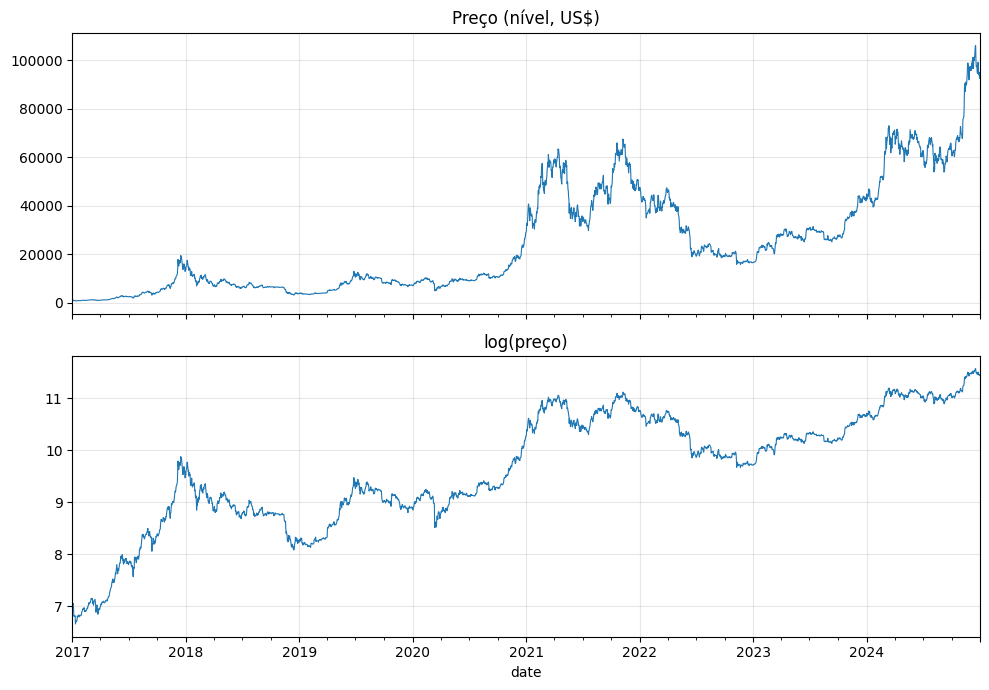

In [5]:
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

# TODA a EDA usa apenas o treino. Decisões (transformação, diferenciação) tomadas olhando o teste
# seriam "vazamento de informação" (data leakage) e inflariam o desempenho aparente.
p  = train.copy()                       # preço em nível
lp = np.log(p).rename("logp")           # log-preço
r  = lp.diff().dropna().rename("ret")   # retorno logarítmico diário = log(P_t) - log(P_{t-1})

chaves = {}                             # acumula os números-chave; impresso na última célula
chaves["n_obs_treino"] = len(p)
chaves["preco_min_treino"], chaves["preco_max_treino"] = float(p.min()), float(p.max())
chaves["razao_ultimo/primeiro_preco"] = float(p.iloc[-1] / p.iloc[0])

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
p.plot(ax=ax[0], lw=.8, title="Preço (nível, US$)")
lp.plot(ax=ax[1], lw=.8, title="log(preço)")
plt.tight_layout(); plt.show()

Célula 5: a variância cresce com o nível? + λ de Box-Cox

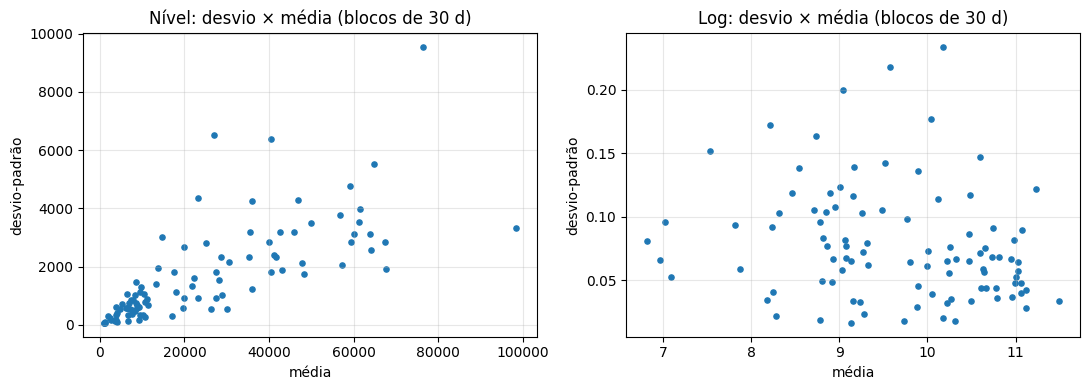

In [6]:
from scipy import stats
from scipy.optimize import minimize_scalar

# Blocos NÃO sobrepostos de W dias: para cada bloco, média e desvio-padrão.
# Se o desvio cresce com a média, a variabilidade é "multiplicativa" -> justifica transformar.
W = 30
def blocos(x, w=W):
    g = x.groupby(np.arange(len(x)) // w)
    d = pd.DataFrame({"media": g.mean(), "dp": g.std(), "n": g.size()})
    return d[d.n == w]                  # descarta o último bloco se incompleto

bn, bl = blocos(p), blocos(lp)
# Spearman = correlação de postos: mede se "quando a média sobe, o desvio sobe", sem supor linearidade.
chaves["spearman_media_vs_dp_NIVEL"] = float(stats.spearmanr(bn.media, bn.dp)[0])
chaves["spearman_media_vs_dp_LOG"]   = float(stats.spearmanr(bl.media, bl.dp)[0])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(bn.media, bn.dp, s=14); ax[0].set(title=f"Nível: desvio × média (blocos de {W} d)", xlabel="média", ylabel="desvio-padrão")
ax[1].scatter(bl.media, bl.dp, s=14); ax[1].set(title=f"Log: desvio × média (blocos de {W} d)", xlabel="média", ylabel="desvio-padrão")
plt.tight_layout(); plt.show()

# λ de Box-Cox por um critério INSPIRADO em Guerrero (1993): escolhe o λ que estabiliza a razão
# (desvio / média^(1-λ)) entre sub-blocos. É implementação PRÓPRIA e simplificada (blocos de 7 dias);
# não é idêntica ao BoxCox.lambda do R, então não comparar este valor com o λ do tutorial.
# Leitura: λ ≈ 0 => log; λ ≈ 1 => nenhuma transformação.
def lambda_guerrero(x, m=7, limites=(-1, 2)):
    x = np.asarray(x, float); n = (len(x) // m) * m
    b = x[-n:].reshape(-1, m)
    mu, sd = b.mean(1), b.std(1, ddof=1)
    def cv(l):
        z = sd / mu ** (1 - l)
        return z.std(ddof=1) / z.mean()
    return minimize_scalar(cv, bounds=limites, method="bounded").x
chaves["lambda_boxcox_guerrero"] = float(lambda_guerrero(p.values))

Célula 6: retornos e normalidade

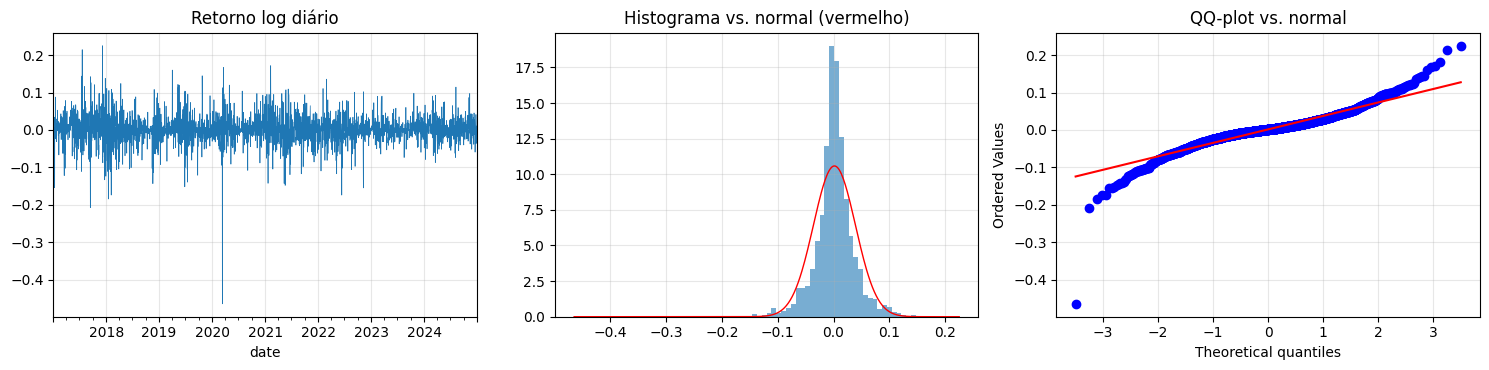

In [7]:
mu, sd = r.mean(), r.std()
chaves.update({
    "ret_media_diaria": float(mu), "ret_desvio_diario": float(sd),
    "ret_assimetria": float(stats.skew(r)),
    "ret_curtose_excesso": float(stats.kurtosis(r)),            # excesso: normal = 0
    "ret_pct_|desvio|>3dp (normal esperaria 0.27)": float((np.abs(r - mu) > 3 * sd).mean() * 100),
    "JarqueBera_pvalor": float(stats.jarque_bera(r).pvalue)})   # H0: assimetria e curtose iguais às da normal

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
r.plot(ax=ax[0], lw=.5, title="Retorno log diário")
ax[1].hist(r, bins=80, density=True, alpha=.6)
xs = np.linspace(r.min(), r.max(), 400); ax[1].plot(xs, stats.norm.pdf(xs, mu, sd), "r", lw=1)
ax[1].set_title("Histograma vs. normal (vermelho)")
stats.probplot(r, dist="norm", plot=ax[2]); ax[2].set_title("QQ-plot vs. normal")
plt.tight_layout(); plt.show()

Célula 7: ACF/PACF

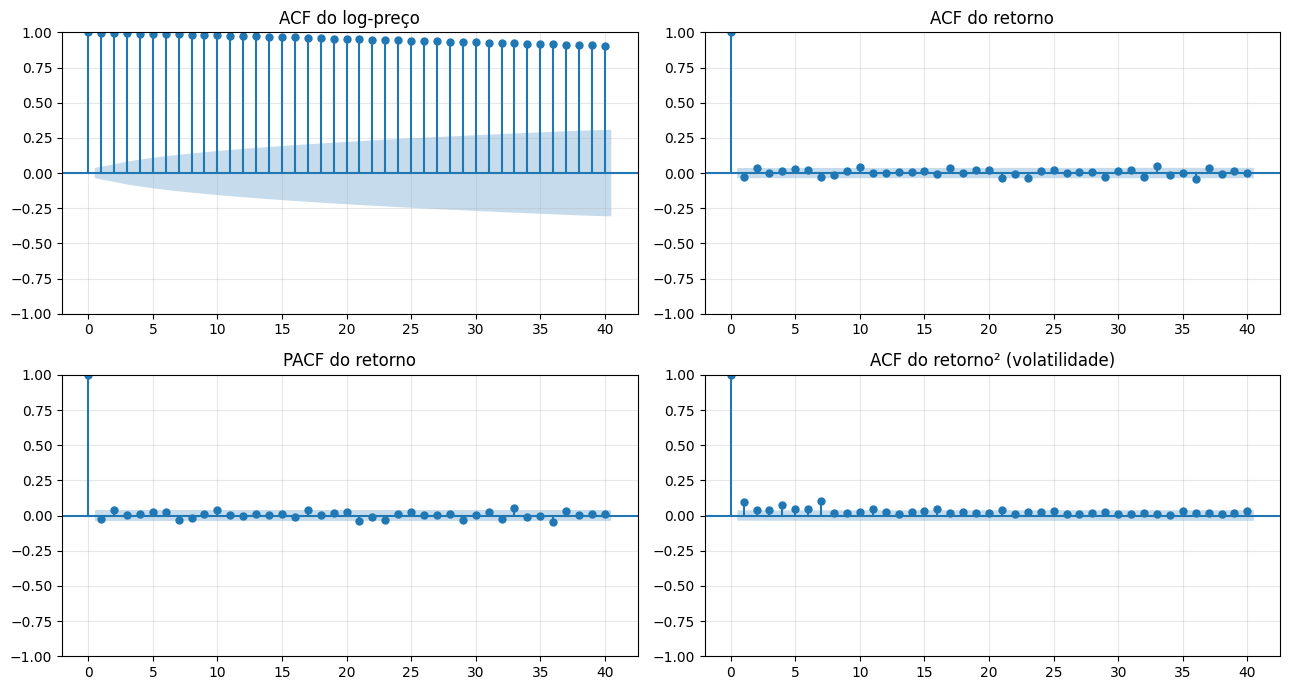

In [8]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ACF = correlação da série com ela mesma defasada k dias; PACF = idem, descontando as defasagens intermediárias.
# As bandas azuis são o intervalo de ~95% sob "ruído branco": barras fora sugerem autocorrelação.
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
plot_acf (lp,    lags=MAX_LAGS, ax=ax[0, 0], title="ACF do log-preço")
plot_acf (r,     lags=MAX_LAGS, ax=ax[0, 1], title="ACF do retorno")
plot_pacf(r,     lags=MAX_LAGS, ax=ax[1, 0], method="ywm", title="PACF do retorno")
plot_acf (r**2,  lags=MAX_LAGS, ax=ax[1, 1], title="ACF do retorno² (volatilidade)")
plt.tight_layout(); plt.show()

Célula 8: testes formais

In [9]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

linhas = []
def add(teste, serie, h0, est, pv, obs=""):
    linhas.append({"teste": teste, "série": serie, "H0": h0, "estatística": round(float(est), 4),
                   "p-valor": float(pv), "rejeita H0 (5%)": bool(pv < ALPHA), "obs": obs})

# ADF e KPSS têm hipóteses nulas OPOSTAS (por isso devem ser lidos em conjunto):
#   ADF : H0 = há raiz unitária (não estacionária)   | KPSS: H0 = estacionária
# regression="c" => em torno de uma constante; "ct" => em torno de constante + tendência linear.
for nome, x, reg in [("log-preço", lp, "c"), ("log-preço", lp, "ct"), ("retorno", r, "c")]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)               # aviso sobre mudança futura do formato de retorno
        a = adfuller(x, regression=reg, autolag="AIC")                    # autolag: escolhe defasagens por AIC
    add(f"ADF ({reg})", nome, "raiz unitária (não estacionária)", a[0], a[1], f"defasagens={a[2]}")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                               # aviso de p-valor fora da tabela do KPSS
        k = kpss(x, regression=reg, nlags="auto")
    h0k = "estacionária" if reg == "c" else "estacionária em torno de tendência"
    add(f"KPSS ({reg})", nome, h0k, k[0], k[1], "p-valor limitado ao intervalo [0.01, 0.10]")

# Ljung-Box: H0 = nenhuma autocorrelação até o lag L (testa as L autocorrelações JUNTAS).
for nome, x in [("retorno", r), ("retorno²", r ** 2)]:
    lb = acorr_ljungbox(x, lags=[10, 20], return_df=True)
    for L in (10, 20):
        add(f"Ljung-Box (lag {L})", nome, "sem autocorrelação até o lag", lb.loc[L, "lb_stat"], lb.loc[L, "lb_pvalue"],
            "assume variância constante (ver versões robustas abaixo)")

import statsmodels.api as sm
from scipy.stats import chi2
from arch import arch_model

# --- 1) Box-Pierce robusto à heterocedasticidade ---
# O Ljung-Box padrão supõe variância constante; com efeito ARCH ele tende a rejeitar DEMAIS.
# Aqui cada autocorrelação ρ_k é padronizada pela variância que ela realmente tem sob ARCH.
# Q* de Lobato-Nankervis-Savin (2001). Sob H0 (sem autocorrelação), Q* ~ χ²(L).
def box_pierce_robusto(x, L):
    x = np.asarray(x, float); x = x - x.mean(); n = len(x); g0 = np.mean(x ** 2)
    q = 0.0
    for k in range(1, L + 1):
        rho = np.sum(x[k:] * x[:-k]) / n / g0
        tau = np.sum(x[k:] ** 2 * x[:-k] ** 2) / n / g0 ** 2     # variância robusta de √n·ρ_k
        q += n * rho ** 2 / tau
    return q, float(chi2.sf(q, L))
for L in (10, 20):
    q, pq = box_pierce_robusto(r, L)
    add(f"Box-Pierce robusto (lag {L})", "retorno", "sem autocorrelação (robusto a ARCH)", q, pq, "Lobato et al. (2001)")

# --- 2) Ljung-Box nos resíduos padronizados de um GARCH(1,1) com t de Student ---
# O GARCH "explica" a volatilidade variável; dividindo o retorno pela volatilidade estimada, sobra um
# resíduo ~ sem ARCH, onde o Ljung-Box volta a ser (aproximadamente) válido.
# arch_model é mais estável numericamente com retornos em % (escala ~1), por isso r*100.
am = arch_model(r * 100, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
z = am.std_resid.dropna()
# Parâmetros do GARCH(1,1)-t. ATENÇÃO às unidades: o retorno entrou em % (r*100), então mu está em %/dia
# e omega em %². alpha = reação a choques recentes; beta = memória da volatilidade passada; nu = graus de liberdade da t
# (quanto menor, mais pesadas as caudas). alpha+beta mede a PERSISTÊNCIA da volatilidade (perto de 1 = choques demoram a passar).
# O erro-padrão de alpha+beta usa a matriz de covariância das estimativas (a soma tem variância Var(a)+Var(b)+2Cov(a,b)).
_par, _cov = am.params, am.param_cov
tab_garch = pd.DataFrame({"estimativa": _par, "erro_padrão": am.std_err, "p-valor": am.pvalues})
_se_ab = float(np.sqrt(_cov.loc["alpha[1]", "alpha[1]"] + _cov.loc["beta[1]", "beta[1]"] + 2 * _cov.loc["alpha[1]", "beta[1]"]))
# Diagnóstico de convergência e do regime de momentos. Se alpha+beta ≈ 1 (volatilidade quase INTEGRADA, IGARCH),
# a variância incondicional não é bem definida; com nu <= 4 a curtose é infinita. Nesses casos, p-valores que dependem de
# momentos finitos (ARCH-LM, Ljung-Box de r², Box-Pierce robusto) valem como evidência QUALITATIVA, não como magnitude exata.
# O GARCH aqui é só DIAGNÓSTICO: não afirmamos estacionariedade da volatilidade.
garch_info = {"convergence_flag (0 = convergiu)": int(am.convergence_flag),
              "alpha+beta": float(_par["alpha[1]"] + _par["beta[1]"]), "nu <= 4": bool(_par["nu"] <= 4)}
tab_garch.loc["alpha[1]+beta[1]"] = [float(_par["alpha[1]"] + _par["beta[1]"]), _se_ab, np.nan]
for nome, x in [("resíduo padronizado GARCH-t", z), ("resíduo padronizado² GARCH-t", z ** 2)]:
    lbz = acorr_ljungbox(x, lags=[10, 20], return_df=True)
    for L in (10, 20):
        add(f"Ljung-Box (lag {L})", nome, "sem autocorrelação até o lag", lbz.loc[L, "lb_stat"],
            lbz.loc[L, "lb_pvalue"], "p aproximado (resíduos estimados)")

# --- ARCH-LM: série centrada + n efetivo conferido ---
# LM = nobs · R² da regressão de x² em x²_{t-1..t-L} (constante incluída); sob H0, LM ~ χ²(L).
# Calculamos "à mão" para REGISTRAR o nobs realmente usado e conferir com o statsmodels
# (aplicado ao RETORNO, não ao preço em nível: falha 4 do tutorial).
def arch_lm_manual(x, L):
    x2 = pd.Series((np.asarray(x, float) - np.mean(x)) ** 2)
    X = pd.concat([x2.shift(k) for k in range(1, L + 1)], axis=1).iloc[L:]   # perde as L primeiras linhas
    y = x2.iloc[L:]
    ols = sm.OLS(y.values, sm.add_constant(X.values)).fit()
    nobs = len(y); lm = nobs * ols.rsquared
    return float(lm), float(chi2.sf(lm, L)), nobs
rc = r - r.mean()                                  # centraliza antes de testar
for L in (5, 10):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        lm_pkg, p_pkg, _, _ = het_arch(rc, nlags=L)
    lm_man, p_man, nobs = arch_lm_manual(rc, L)   # (nomes distintos de `p`, que guarda o preço da Etapa 2)
    add(f"ARCH-LM (lags={L})", "retorno (centrado)", "variância condicional constante (sem ARCH)", lm_man, p_man,
        f"LM=nobs·R², nobs={nobs}; het_arch: LM={lm_pkg:.4f}, p={p_pkg:.4g}")

tab_testes = pd.DataFrame(linhas)

Célula 9: sazonalidade nos retornos

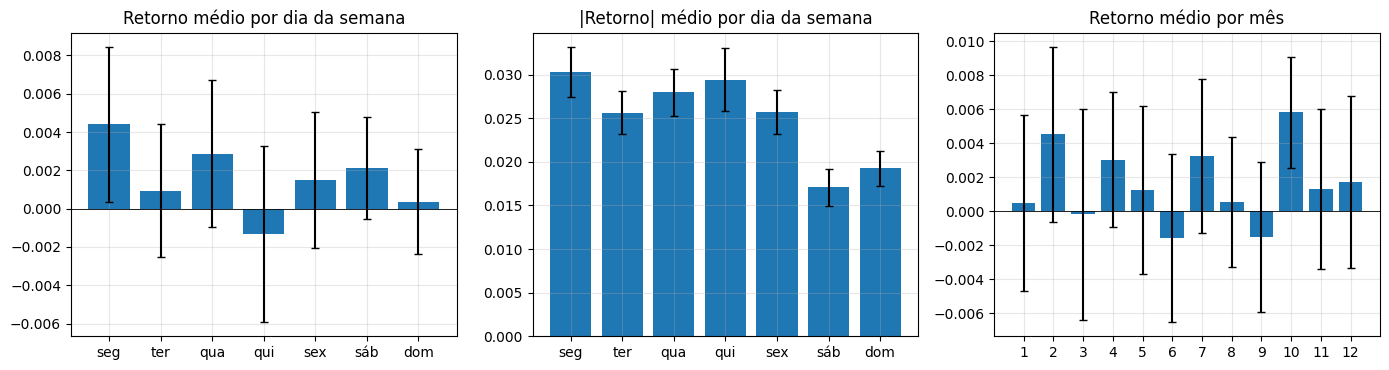

In [10]:
d = pd.DataFrame({"ret": r}); d["abs"] = d.ret.abs()
d["dow"] = d.index.dayofweek; d["mes"] = d.index.month
dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]

# Kruskal-Wallis: H0 = todos os grupos (dias/meses) vêm da mesma distribuição. É a versão
# não-paramétrica da ANOVA (não exige normalidade, o que seria inadequado para retornos).
# ATENÇÃO: o KW supõe observações independentes; |retorno| é fortemente dependente (volatilidade em
# clusters), então esse p SUPERESTIMA a evidência. Por isso as chaves levam o rótulo 'indicativo'.
def kw(col, by): return float(stats.kruskal(*[g[col].values for _, g in d.groupby(by)]).pvalue)
chaves["KW_indicativo_retorno_por_diaSemana_p"]   = kw("ret", "dow")
chaves["KW_indicativo_|retorno|_por_diaSemana_p"] = kw("abs", "dow")
chaves["KW_indicativo_retorno_por_mes_p"]         = kw("ret", "mes")

# Complemento sem supor independência: regressão nas dummies do grupo com erros-padrão HAC
# (Newey-West: corrigem autocorrelação e heterocedasticidade) + teste de Wald (χ²) de que TODAS as
# médias dos grupos são iguais.
import statsmodels.api as sm
def wald_hac(col, by, maxlags=14):
    X = sm.add_constant(pd.get_dummies(d[by], drop_first=True).astype(float))
    res = sm.OLS(d[col].values, X.values).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    R = np.eye(X.shape[1])[1:]                       # todos os coeficientes, exceto a constante, = 0
    try:
        w = res.wald_test(R, use_f=False, scalar=True)
    except TypeError:                                # versões antigas do statsmodels não têm 'scalar'
        w = res.wald_test(R, use_f=False)
    return float(w.pvalue)
chaves["HAC_Wald_retorno_por_diaSemana_p"]   = wald_hac("ret", "dow")
chaves["HAC_Wald_|retorno|_por_diaSemana_p"] = wald_hac("abs", "dow")
chaves["HAC_Wald_retorno_por_mes_p"]         = wald_hac("ret", "mes")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, (col, by, tit) in zip(ax, [("ret", "dow", "Retorno médio por dia da semana"),
                                  ("abs", "dow", "|Retorno| médio por dia da semana"),
                                  ("ret", "mes", "Retorno médio por mês")]):
    g = d.groupby(by)[col]; m, e = g.mean(), 1.96 * g.sem()          # barras = média ± IC 95%
    a.bar(m.index, m.values, yerr=e.values, capsize=3); a.axhline(0, c="k", lw=.6); a.set_title(tit)
ax[0].set_xticks(range(7), dias); ax[1].set_xticks(range(7), dias); ax[2].set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

Célula 10: tabelas-resumo da Etapa 2 (cole aqui)

In [11]:
def fmt_p(v, nome=""):
    # KPSS: o statsmodels trunca o p-valor em [0.01, 0.10]; esses extremos são LIMITES, não valores exatos.
    if "KPSS" in nome:
        if v <= 0.0101: return "≤0.01"
        if v >= 0.0999: return "≥0.10"
    return "<1e-16" if v < 1e-16 else f"{v:.4g}"      # "0" impresso seria só underflow numérico

def fmt_val(k, v):
    if isinstance(v, (int, np.integer)): return str(v)
    return fmt_p(v) if (k.endswith("_p") or "pvalor" in k) else f"{v:.6g}"

tab_chaves = pd.DataFrame({"valor": {k: fmt_val(k, v) for k, v in chaves.items()}})
tf = tab_testes.copy()
tf["p-valor"] = [fmt_p(v, t) for v, t in zip(tab_testes["p-valor"], tab_testes["teste"])]
print("=== NÚMEROS-CHAVE ===");  print(tab_chaves.to_string())
print("\n=== TESTES FORMAIS ==="); print(tf.to_string(index=False))
tg = tab_garch.copy(); tg["p-valor"] = [fmt_p(v) if pd.notna(v) else "" for v in tab_garch["p-valor"]]
print("\n=== GARCH(1,1)-t (retorno em %) ==="); print(tg.to_string(float_format=lambda v: f"{v:.5g}"))
print("\n=== GARCH: diagnóstico ===")
for k, v in garch_info.items(): print(f"{k}: {v:.6g}" if isinstance(v, float) else f"{k}: {v}")
print("Nota: se alpha+beta ≈ 1 ou nu <= 4, os p-valores de ARCH-LM/Ljung-Box(r²) valem só como evidência qualitativa (momentos podem não existir).")

=== NÚMEROS-CHAVE ===
                                                   valor
n_obs_treino                                        2922
preco_min_treino                                 777.757
preco_max_treino                                  106141
razao_ultimo/primeiro_preco                       93.586
spearman_media_vs_dp_NIVEL                      0.847123
spearman_media_vs_dp_LOG                       -0.270132
lambda_boxcox_guerrero                           0.11513
ret_media_diaria                              0.00155388
ret_desvio_diario                              0.0376958
ret_assimetria                                 -0.666965
ret_curtose_excesso                              11.3321
ret_pct_|desvio|>3dp (normal esperaria 0.27)     1.40363
JarqueBera_pvalor                                 <1e-16
KW_indicativo_retorno_por_diaSemana_p             0.6546
KW_indicativo_|retorno|_por_diaSemana_p           <1e-16
KW_indicativo_retorno_por_mes_p                   0.9006
HAC_Wald_

Etapa 3: decomposição da série (MSTL no log-preço, só treino)

Célula 11: decomposição MSTL e força dos componentes

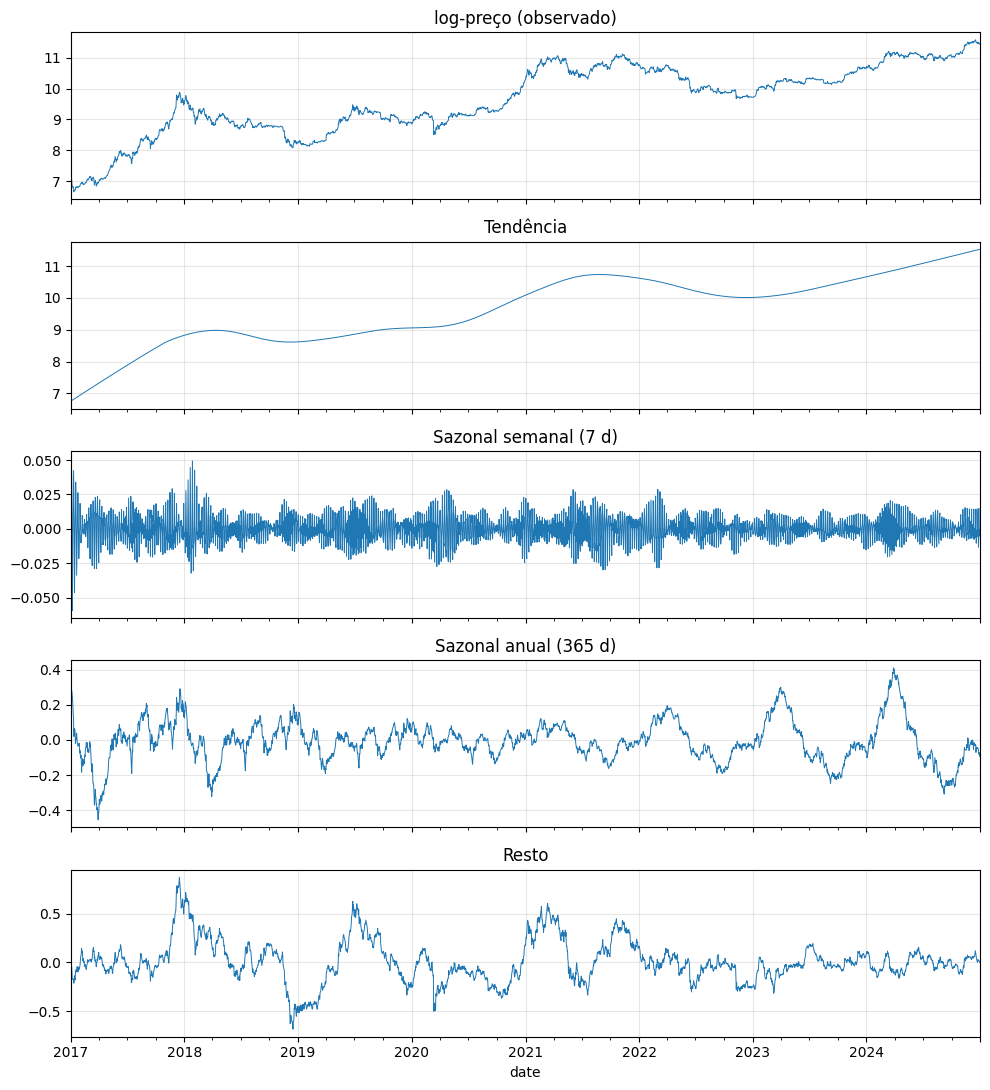

In [12]:
from statsmodels.tsa.seasonal import MSTL

# MSTL = STL (Seasonal-Trend decomposition using Loess) estendida a VÁRIAS sazonalidades.
# log-preço = tendência + sazonal(7 dias) + sazonal(365 dias) + resto.
# Usamos o LOG: decomposição ADITIVA do log = decomposição MULTIPLICATIVA do preço (justificado na Etapa 2).
# ATENÇÃO: é ferramenta DESCRITIVA. O alisamento é bilateral (a tendência em t usa dados DEPOIS de t),
# então ela NÃO é um modelo de previsão. Os "windows" (suavidade de cada sazonalidade; janelas curtas deixam o padrão
# sazonal VARIAR rápido ao longo do tempo) são os PADRÃO do statsmodels e ficam REGISTRADOS na Célula 13.
# Com ~8 anos há só ~8 ciclos anuais: a sazonalidade de 365 dias é pouco identificável.
# MSTL_KW é usado também no controle por permutação, para que observado e nulo usem EXATAMENTE a mesma especificação.
MSTL_KW = dict(periods=(7, 365))
modelo_mstl = MSTL(lp, **MSTL_KW)
mstl = modelo_mstl.fit()
trend, resid = mstl.trend, mstl.resid
s7, s365 = mstl.seasonal.iloc[:, 0], mstl.seasonal.iloc[:, 1]

fig, ax = plt.subplots(5, 1, figsize=(10, 11), sharex=True)
for a, (serie, tit) in zip(ax, [(lp, "log-preço (observado)"), (trend, "Tendência"),
                                (s7, "Sazonal semanal (7 d)"), (s365, "Sazonal anual (365 d)"),
                                (resid, "Resto")]):
    serie.plot(ax=a, lw=.7, title=tit)
plt.tight_layout(); plt.show()

# "Força" (Wang, Smith & Hyndman, 2006): F = max(0, 1 - Var(resto) / Var(componente + resto)).
# F ≈ 0: componente indistinguível do ruído; F ≈ 1: componente domina o resto.
def forca(comp, resto):
    return float(max(0.0, 1 - np.var(resto) / np.var(comp + resto)))

# Correlação do perfil sazonal anual entre anos consecutivos (anos alinhados pelo dia do calendário, sem 29/fev).
# CUIDADO: ela tende a ser ALTA POR CONSTRUÇÃO no MSTL (ajusta um perfil por dia do calendário e, com janela maior que o nº
# de anos, o perfil fica quase igual de um ano para outro mesmo com ruído). Só tem valor COMPARADA com o nulo, e mesmo assim
# não discrimina padrão de ruído se o nulo também der correlação alta. A evidência principal é F_S365 vs. nulo.
def corr_anos(s):
    d = s[~((s.index.month == 2) & (s.index.day == 29))].to_frame("v")
    d["ano"], d["md"] = d.index.year, d.index.strftime("%m-%d")
    piv = d.pivot(index="md", columns="ano", values="v").dropna(axis=1)     # só anos completos
    cols = list(piv.columns)
    return float(np.mean([piv[a].corr(piv[b]) for a, b in zip(cols[:-1], cols[1:])]))

obs = {"F_T": forca(trend, resid), "F_S7": forca(s7, resid), "F_S365": forca(s365, resid),
       "corr_anos_S365": corr_anos(s365)}

Célula 12: controle por permutação (o que o ruído sozinho produz)

50/200 permutações
100/200 permutações
150/200 permutações
200/200 permutações


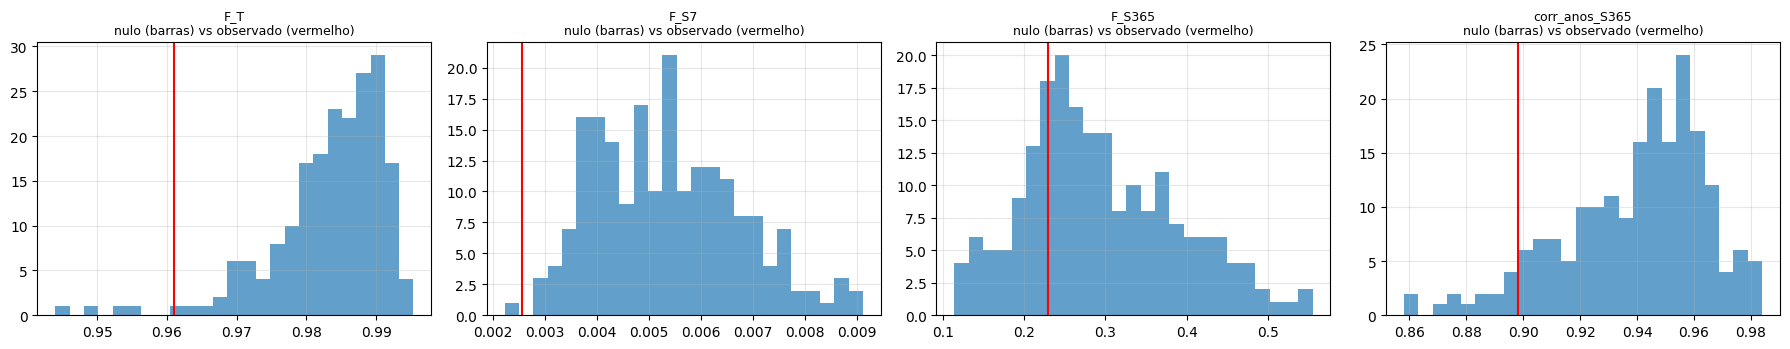

In [13]:
# Hipótese nula: os retornos são i.i.d. (passeio aleatório com deriva). Embaralhar a ORDEM dos retornos
# preserva média, desvio e caudas pesadas, mas destrói qualquer padrão temporal (inclusive o agrupamento de
# volatilidade, que é uma limitação deste controle). Refazemos a decomposição em cada série embaralhada.
# Gerador próprio com a seed: independente da ordem de execução das outras células.
rng = np.random.default_rng(SEED)

def forcas(y):
    m = MSTL(y, **MSTL_KW).fit()
    return (forca(m.trend, m.resid), forca(m.seasonal.iloc[:, 0], m.resid), forca(m.seasonal.iloc[:, 1], m.resid),
            corr_anos(m.seasonal.iloc[:, 1]))

nulo = []
for i in range(N_PERM):                                   # pode levar alguns minutos
    rp = rng.permutation(r.values)
    y = pd.Series(lp.iloc[0] + np.concatenate([[0.0], np.cumsum(rp)]), index=lp.index)
    nulo.append(forcas(y))
    if (i + 1) % 50 == 0: print(f"{i + 1}/{N_PERM} permutações")
nulo = pd.DataFrame(nulo, columns=["F_T", "F_S7", "F_S365", "corr_anos_S365"])

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, c in zip(ax, nulo.columns):
    a.hist(nulo[c], bins=25, alpha=.7); a.axvline(obs[c], c="r"); a.set_title(f"{c}\nnulo (barras) vs observado (vermelho)", fontsize=9)
plt.tight_layout(); plt.show()

Célula 13: tabela-resumo da Etapa 3 (cole aqui)

**Como ler esta tabela (guia conceitual, sem interpretar os números)**
- *p_cauda_dir*: fração de séries embaralhadas (puro ruído) com valor **maior ou igual** ao observado. Para a sazonalidade a pergunta natural é "é mais forte que o ruído?", e é essa cauda que responde. *p_cauda_esq* é a pergunta oposta ("é mais fraco que o ruído?"). Um p alto numa cauda **não** significa "efeito inexistente"; significa só que o teste daquela cauda não rejeitou.
- **F_T não prova tendência determinística.** Um alisador (loess) extrai uma "tendência forte" até de um passeio aleatório puro: o próprio nulo mostra o F_T típico do ruído. Isso importa porque a tendência do Prophet é linear por partes.
- **Amplitude (máx−mín) engana** quando há pontos extremos ou efeito de borda: use o desvio-padrão, os percentis e as datas do máximo/mínimo. *corr_anos_S365* (correlação do perfil sazonal anual entre anos consecutivos) tende a ser **alta por construção**: o MSTL ajusta um perfil por dia do calendário e, com janela maior que o número de anos, o perfil fica quase igual de um ano para o outro mesmo com ruído. O nulo (retornos embaralhados) permite conferir isso; se o nulo também der correlação alta, a métrica **não discrimina** padrão anual de ruído. A conclusão sobre sazonalidade anual deve se apoiar em **F_S365 vs. nulo** e na **estabilidade do nível** do S365 (tabelas "S365 por ano" e "S365 no dia do calendário do mínimo"). Se o nível nesse dia do calendário mudar de sinal ao longo dos anos, a forma pode se repetir enquanto o nível deriva; a causa seria hipótese, não verificada.
- O **resto** é o nível do log-preço em relação à tendência (contém swings de meses), não ruído diário; não compare seu desvio com o do retorno diário.
- O nulo i.i.d. destrói o agrupamento de volatilidade; é um controle, não um modelo realista do Bitcoin.


In [14]:
# p de permutação nas DUAS caudas. O observado pode estar abaixo do nulo, e um p unicaudal à direita não diz isso:
#   p_cauda_dir = (1 + #{nulo >= obs}) / (1 + N_PERM)  -> "o observado é MAIOR que o ruído?"   (pergunta natural p/ sazonalidade)
#   p_cauda_esq = (1 + #{nulo <= obs}) / (1 + N_PERM)  -> "o observado é MENOR que o ruído?"
# O mínimo possível de cada um é 1/(1+N_PERM). Erro-padrão de Monte Carlo de um p: sqrt(p(1-p)/N_PERM), no PIOR caso (p=0.5)
# sqrt(0.25/N_PERM); o intervalo de 95% nesse pior caso é ≈ ±1.96 vezes isso. (Não é um "máximo": é uma medida de incerteza.)
linhas3 = []
for c in nulo.columns:
    p_dir = (1 + (nulo[c] >= obs[c]).sum()) / (1 + N_PERM)
    p_esq = (1 + (nulo[c] <= obs[c]).sum()) / (1 + N_PERM)
    linhas3.append({"métrica": c, "observado": round(obs[c], 4), "nulo_mediana": round(nulo[c].median(), 4),
                    "nulo_p5": round(nulo[c].quantile(.05), 4), "nulo_p95": round(nulo[c].quantile(.95), 4),
                    "p_cauda_dir": round(float(p_dir), 4), "p_cauda_esq": round(float(p_esq), 4)})
print("=== MSTL: especificação usada ===")
print(f"periods={modelo_mstl.periods}  windows={modelo_mstl.windows}  iterate={modelo_mstl.iterate}  (statsmodels {statsmodels.__version__})")
print(f"\n=== FORÇA DOS COMPONENTES vs. NULO (retornos embaralhados; N_PERM={N_PERM}) ===")
print(pd.DataFrame(linhas3).to_string(index=False))
_se = np.sqrt(0.25 / N_PERM)
print(f"Erro-padrão de Monte Carlo no pior caso (p=0,5) ≈ {_se:.3f}; IC 95% no pior caso ≈ ±{1.96 * _se:.3f}")

# Amplitudes em unidades do log-preço (≈ variação percentual).
#  - O MÁXIMO−MÍNIMO é sensível a UM ponto extremo (efeito de borda no início/fim da série, picos isolados); por isso
#    reportamos também dp, percentis 5-95 e as DATAS do máximo e do mínimo, para ver se são pontos de borda.
#  - (máx−mín)/dp ≈ 2,83 para uma senoide estável; valores muito acima indicam amplitude instável ou pontos extremos.
#  - O "resto" é o desvio do NÍVEL do log-preço em relação à tendência (contém swings de meses); NÃO é ruído diário
#    nem é comparável ao desvio do retorno diário, que mede variação de UM dia para o outro (outra escala).
def resumo_amp(s, nome):
    rng_ = float(s.max() - s.min())
    return {f"{nome}: dp": float(s.std()), f"{nome}: p5": float(s.quantile(.05)), f"{nome}: p95": float(s.quantile(.95)),
            f"{nome}: máx-mín": rng_, f"{nome}: (máx-mín)/dp": rng_ / float(s.std()),
            f"{nome}: data do máx": s.idxmax().date(), f"{nome}: data do mín": s.idxmin().date()}
amp = {}
amp.update(resumo_amp(s7, "sazonal_7d")); amp.update(resumo_amp(s365, "sazonal_365d"))
amp["resto: dp (nível em torno da tendência; NÃO é volatilidade diária)"] = float(resid.std())
amp["REFERÊNCIA, outra escala: dp do retorno diário (Etapa 2)"] = float(r.std())
print("\n=== AMPLITUDES ===")
print(pd.Series({k: (f"{v:.4g}" if isinstance(v, float) else str(v)) for k, v in amp.items()}, name="valor").to_string())

# Instabilidade do NÍVEL do componente anual (S365): se o perfil fosse estável, a mesma época do calendário teria
# valores parecidos em todos os anos. Médias anuais afastadas de 0, ou sinais trocando no mesmo dia do calendário, indicam
# deriva de nível no componente. A CAUSA não é verificada (hipótese: a suavização por dia do calendário, com janela maior que
# o nº de anos, pode estar absorvendo deriva de longo prazo).
por_ano = s365.groupby(s365.index.year).agg(média="mean", mínimo="min", máximo="max")
print("\n=== S365 POR ANO (log-preço) ===")
print(por_ano.to_string(float_format=lambda v: f"{v:.4f}"))
md_min = s365.idxmin().strftime("%m-%d")
no_dia = s365[s365.index.strftime("%m-%d") == md_min]; no_dia.index = no_dia.index.year
print(f"\n=== S365 NO DIA DO CALENDÁRIO DO MÍNIMO ({md_min}), por ano ===")
print(no_dia.to_string(float_format=lambda v: f"{v:.4f}"))


=== MSTL: especificação usada ===
periods=[7, 365]  windows=(11, 15)  iterate=2  (statsmodels 0.15.0)

=== FORÇA DOS COMPONENTES vs. NULO (retornos embaralhados; N_PERM=200) ===
       métrica  observado  nulo_mediana  nulo_p5  nulo_p95  p_cauda_dir  p_cauda_esq
           F_T     0.9610        0.9851   0.9690    0.9926       0.9801       0.0249
          F_S7     0.0026        0.0053   0.0034    0.0077       0.9950       0.0100
        F_S365     0.2294        0.2775   0.1521    0.4572       0.7562       0.2488
corr_anos_S365     0.8983        0.9443   0.8940    0.9763       0.9303       0.0746
Erro-padrão de Monte Carlo no pior caso (p=0,5) ≈ 0.035; IC 95% no pior caso ≈ ±0.069

=== AMPLITUDES ===
sazonal_7d: dp                                                          0.009348
sazonal_7d: p5                                                          -0.01458
sazonal_7d: p95                                                          0.01484
sazonal_7d: máx-mín                             

# Etapa 4: benchmarks simples e Prophet com defaults (origem única)

**Aviso de método.** Esta etapa reproduz o *desenho do tutorial* (um único treino → previsão dos `H_TEST` dias do teste) apenas para comparar o Prophet com benchmarks. **Transparência sobre o teste:** ele é visto aqui pela primeira vez e será visto de novo na Etapa 6 (duas vezes). Os resultados desta etapa já são conhecidos quando a lista de variantes da Etapa 5 é definida; portanto **não é possível garantir que o teste não influenciou o desenho dessa lista** (ver a nota na Etapa 5). A partir daqui, nenhuma escolha de hiperparâmetro será feita olhando o teste: ajustes usam validação de origem móvel *somente dentro do treino*. As conclusões desta etapa valem só para esta origem e este horizonte (uma única trajetória, não são conclusões gerais); a comparação tem muita variância; os testes de significância (Diebold-Mariano) vêm na Etapa 6.

**O que cada gráfico mostra e por que importa**
- *Previsões vs. realizado (nível)*: coloca as 5 previsões de `H_TEST` dias sobre o preço real do período de teste. Mostra, a olho nu, que forma cada método projeta (reta, repetição semanal, curva do Prophet) e se algo foge do plausível. Importa porque RMSE sozinho esconde *como* o erro aparece.
- *Erro absoluto por horizonte*: mostra como o erro cresce com a distância até a origem. Importa porque para preços o erro cresce com o horizonte (cresce com √h num passeio aleatório), e porque um modelo pode ganhar em horizontes curtos e perder nos longos.

**Glossário (resumo)**
- **Naive**: previsão = último preço observado, repetido em todo o horizonte. É o benchmark natural para um passeio aleatório.
- **Drift**: naive + uma inclinação constante, a variação média por dia do treino (último − primeiro)/(n − 1).
- **Naive sazonal (7 d)**: repete a última semana observada.
- **RMSE** (raiz do erro quadrático médio): penaliza erros grandes; está na unidade do preço (US$). **MAE**: média do erro absoluto, também em US$.
- **MASE**: MAE dividido pelo MAE do naive de 1 passo **dentro do treino**; não tem unidade. Aqui o horizonte é de até 365 dias, então valores bem acima de 1 são esperados e **não** significam "pior que o naive": a comparação justa é com o naive *no mesmo horizonte* (coluna *RMSE_rel_naive*).
- **Viés (ME)**: média do erro (realizado − previsto). Positivo: o método subestimou o preço em média.
- **Cobertura empírica**: fração dos dias do teste em que o preço real ficou dentro do intervalo de previsão. Se o intervalo é de 80%, uma cobertura muito diferente de 80% indica intervalos mal calibrados.
- **Changepoints**: pontos onde a tendência linear por partes do Prophet pode mudar de inclinação.

Célula 14: benchmarks (naive, drift, naive sazonal) e funções de métrica

In [15]:
# ===== ETAPA 4 · benchmarks =====
# Previsões de h = 1..H_TEST passos à frente a partir da MESMA origem (último dia do treino), usando só o treino.
y_tr, y_te = train.values.astype(float), test.values.astype(float)
h = np.arange(1, H_TEST + 1)
ultimo = y_tr[-1]

prev = {}
prev["naive"] = np.full(H_TEST, ultimo)                            # último valor observado
inclin = (y_tr[-1] - y_tr[0]) / (len(y_tr) - 1)                    # variação média diária do treino
prev["drift"] = ultimo + inclin * h                                # naive + inclinação (deriva), em US$
prev["naive_sazonal_7d"] = np.tile(y_tr[-7:], int(np.ceil(H_TEST / 7)))[:H_TEST]   # repete a última semana
assert all(len(v) == H_TEST for v in prev.values()) and len(y_te) == H_TEST

# MASE: escala = MAE do naive de 1 passo DENTRO do treino (nunca usa o teste).
escala_mase = float(np.mean(np.abs(np.diff(y_tr))))

def metricas(y, yhat):
    e = y - yhat
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e))),
            "MASE": float(np.mean(np.abs(e)) / escala_mase), "viés_ME": float(np.mean(e))}

Célula 15: Prophet com defaults (nível) e Prophet com defaults em log

In [16]:
# ===== ETAPA 4 · Prophet =====
# Duas variantes ESPECIFICADAS DE ANTEMÃO (não escolhidas pelo teste):
#   (a) prophet_nivel: Prophet() com TODOS os defaults, em preço (replica o tutorial; falhas 1 e 6)
#   (b) prophet_log  : idêntico, mudando APENAS a transformação (ajusta log(preço) e volta com exp)
# O exp(yhat) é a MEDIANA da previsão do preço, não a média (a média de uma lognormal é maior); os dois
# diferem em exp(σ²/2). Usamos a mediana de propósito: é o que sai direto do modelo, sem correção ad hoc.
import logging
from prophet import Prophet
logging.getLogger("cmdstanpy").setLevel(logging.WARNING); logging.getLogger("prophet").setLevel(logging.WARNING)

df_tr = pd.DataFrame({"ds": train.index, "y": train.values.astype(float)})

def ajusta_prophet(df, usar_log):
    d = df.copy()
    if usar_log: d["y"] = np.log(d["y"])
    reseed()                                  # antes do ajuste (repetibilidade)
    m = Prophet()                             # DEFAULTS: nada é passado de propósito
    m.fit(d)
    fut = m.make_future_dataframe(periods=H_TEST, freq="D", include_history=False)
    assert (fut["ds"].values == test.index.values).all(), "datas futuras != datas do teste"
    reseed()                                  # imediatamente antes do predict: os intervalos vêm de simulação
    fc = m.predict(fut)[["ds", "yhat", "yhat_lower", "yhat_upper"]].copy()
    if usar_log:
        fc[["yhat", "yhat_lower", "yhat_upper"]] = np.exp(fc[["yhat", "yhat_lower", "yhat_upper"]])
    return m, fc

m_niv, fc_niv = ajusta_prophet(df_tr, usar_log=False)
m_log, fc_log = ajusta_prophet(df_tr, usar_log=True)
prev["prophet_nivel"], prev["prophet_log"] = fc_niv["yhat"].values, fc_log["yhat"].values

def config(m):
    # Registra o que o modo "auto" realmente decidiu (falha 6): é regra pela extensão/frequência dos dados, não um teste.
    return {"growth": m.growth, "seasonality_mode": m.seasonality_mode,
            "sazonalidades_ativas": ", ".join(f"{k}(fourier={v['fourier_order']})" for k, v in m.seasonalities.items()),
            "feriados (holidays)": "nenhum" if m.holidays is None else "definidos",
            "n_changepoints (pedido)": m.n_changepoints, "changepoints_efetivos": len(m.changepoints),
            "changepoint_range": m.changepoint_range, "changepoint_prior_scale": m.changepoint_prior_scale,
            "seasonality_prior_scale": m.seasonality_prior_scale, "interval_width": m.interval_width,
            "uncertainty_samples": m.uncertainty_samples, "mcmc_samples": m.mcmc_samples}

Célula 16: tabelas-resumo da Etapa 4 (cole aqui)

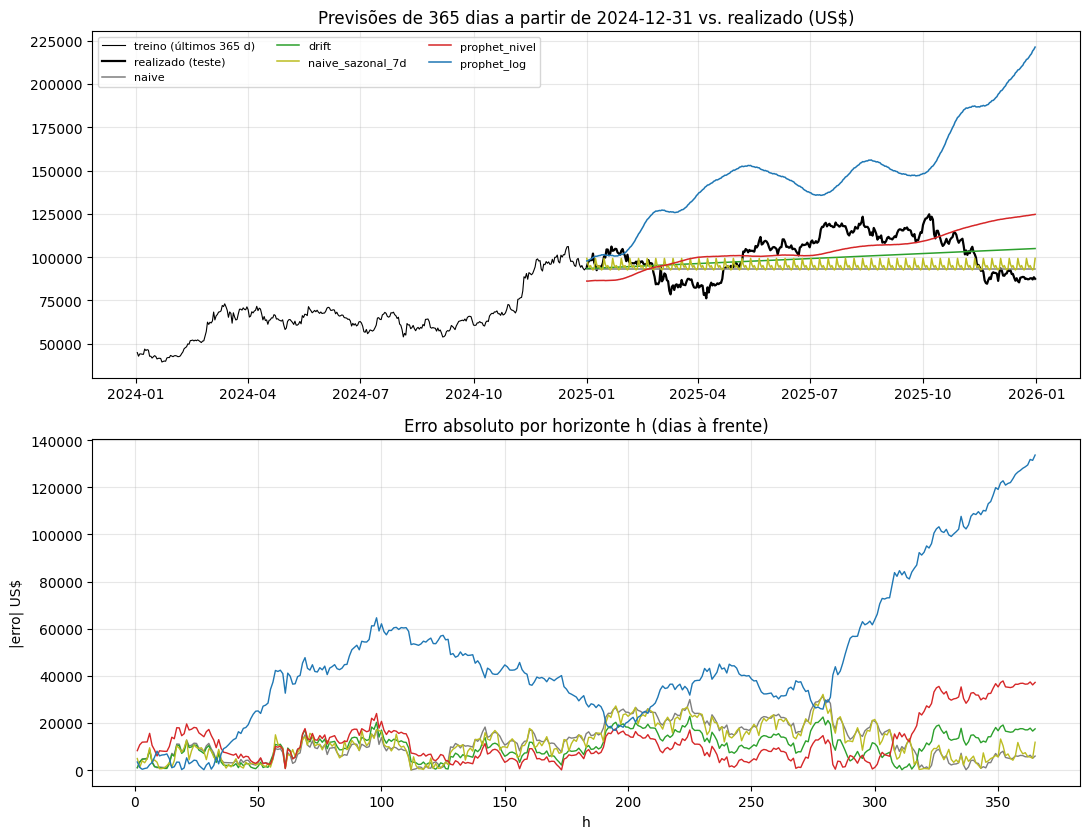

=== MÉTRICAS NO TESTE (origem única, h=1..365; escala MASE=589.19 US$) ===
                       RMSE        MAE   MASE     viés_ME  RMSE_rel_naive
naive            14,325.738 12,097.464 20.532   8,212.719           1.000
drift            11,560.531 10,196.588 17.306   2,421.945           0.807
naive_sazonal_7d 13,690.360 11,632.202 19.743   6,768.885           0.956
prophet_nivel    15,365.289 12,168.992 20.654  -2,526.262           1.073
prophet_log      56,336.203 47,218.100 80.141 -47,009.692           3.933

=== DRIFT: inclinação diária estimada no treino (US$/dia) = 31.6436 ===

=== CONFIGURAÇÃO DO PROPHET (modo auto, defaults) ===
                                                 prophet_nivel                            prophet_log
growth                                                  linear                                 linear
seasonality_mode                                      additive                               additive
sazonalidades_ativas     yearly(fourier=10), we

In [17]:
# ===== ETAPA 4 · gráficos e tabelas =====
ordem = ["naive", "drift", "naive_sazonal_7d", "prophet_nivel", "prophet_log"]
cores = dict(zip(ordem, ["tab:gray", "tab:green", "tab:olive", "tab:red", "tab:blue"]))

fig, ax = plt.subplots(2, 1, figsize=(11, 8.5))
ax[0].plot(train.index[-H_TEST:], train.values[-H_TEST:], c="k", lw=.8, label=f"treino (últimos {H_TEST} d)")
ax[0].plot(test.index, test.values, c="k", lw=1.6, label="realizado (teste)")
for k in ordem: ax[0].plot(test.index, prev[k], c=cores[k], lw=1.1, label=k)
ax[0].set_title(f"Previsões de {H_TEST} dias a partir de {TRAIN_END.date()} vs. realizado (US$)"); ax[0].legend(ncol=3, fontsize=8)
for k in ordem: ax[1].plot(h, np.abs(y_te - prev[k]), c=cores[k], lw=1, label=k)
ax[1].set_title("Erro absoluto por horizonte h (dias à frente)"); ax[1].set_xlabel("h"); ax[1].set_ylabel("|erro| US$")
plt.tight_layout(); plt.show()

# --- tabela de métricas (todas na MESMA origem e no MESMO teste) ---
tm = pd.DataFrame({k: metricas(y_te, prev[k]) for k in ordem}).T
tm["RMSE_rel_naive"] = tm["RMSE"] / tm.loc["naive", "RMSE"]      # >1: pior que o naive; <1: melhor
print("=== MÉTRICAS NO TESTE (origem única, h=1..%d; escala MASE=%.2f US$) ===" % (H_TEST, escala_mase))
print(tm.to_string(float_format=lambda v: f"{v:,.3f}"))

# --- parâmetros do drift e configuração do Prophet ---
print("\n=== DRIFT: inclinação diária estimada no treino (US$/dia) = %.4f ===" % inclin)
print("\n=== CONFIGURAÇÃO DO PROPHET (modo auto, defaults) ===")
print(pd.DataFrame({"prophet_nivel": config(m_niv), "prophet_log": config(m_log)}).to_string())

# --- Âncora e crescimento implícito das previsões ---
# yhat_h1/último_treino mostra se o método "ancora" no último preço (naive/drift ≈ 1; Prophet não ancora).
ult = float(y_tr[-1])
anc = pd.DataFrame({k: {"yhat_h1": prev[k][0], "real_h1": y_te[0], "erro_h1(real-yhat)": y_te[0] - prev[k][0],
                        "yhat_h1/último_treino": prev[k][0] / ult, "yhat_h_final": prev[k][-1],
                        "razão_final/inicial": prev[k][-1] / prev[k][0], "média_das_previsões": float(np.mean(prev[k])),
                        "cresc_log_diário_implícito": (np.log(prev[k][-1]) - np.log(prev[k][0])) / (H_TEST - 1)}
                    for k in ordem}).T
print("\n=== ÂNCORA E CRESCIMENTO IMPLÍCITO (último preço do treino = %.2f US$) ===" % ult)
print(anc.to_string(float_format=lambda v: f"{v:,.4f}"))

# --- Erro por faixa de horizonte (liga a Etapa 4 ao CV_HORIZON da Etapa 5) ---
# Faixas definidas por CV_HORIZON, 90 e H_TEST. RMSE/MAE em US$ e RMSE em LOG (log-erro = log(real) - log(previsto)).
bordas = sorted({0, CV_HORIZON, 90, H_TEST}); bordas = [b for b in bordas if b <= H_TEST]
faixas = list(zip(bordas[:-1], bordas[1:]))
def por_faixa(fun):
    return pd.DataFrame({f"h {a + 1}-{b}": {k: fun(y_te[a:b], prev[k][a:b]) for k in ordem} for a, b in faixas})
rmse_ = lambda y, f: float(np.sqrt(np.mean((y - f) ** 2)))
mae_ = lambda y, f: float(np.mean(np.abs(y - f)))
rmse_log_ = lambda y, f: float(np.sqrt(np.mean((np.log(y) - np.log(np.maximum(f, 1.0))) ** 2)))
print("\n=== RMSE (US$) POR FAIXA DE HORIZONTE ===");  print(por_faixa(rmse_).to_string(float_format=lambda v: f"{v:,.1f}"))
print("\n=== MAE (US$) POR FAIXA DE HORIZONTE ===");   print(por_faixa(mae_).to_string(float_format=lambda v: f"{v:,.1f}"))
print("\n=== RMSE EM LOG POR FAIXA DE HORIZONTE ===");  print(por_faixa(rmse_log_).to_string(float_format=lambda v: f"{v:.4f}"))

# --- intervalos (prévia da Etapa 8: só números, sem ajuste) ---
def info_int(fc):
    lo, up = fc["yhat_lower"].values, fc["yhat_upper"].values
    return {"cobertura_empírica": float(np.mean((y_te >= lo) & (y_te <= up))),
            "largura_média_US$": float(np.mean(up - lo)),
            "%dias_limite_inferior<0": float(100 * np.mean(lo < 0)), "min_limite_inferior": float(lo.min())}
print("\n=== INTERVALOS DO PROPHET (nominal = %.0f%%) ===" % (100 * m_niv.interval_width))
print(pd.DataFrame({"prophet_nivel": info_int(fc_niv), "prophet_log": info_int(fc_log)}).to_string(float_format=lambda v: f"{v:,.4f}"))

# Etapa 5: validação de origem móvel (rolling-origin), só dentro do treino

**Regra de ouro.** Esta etapa lê **somente `train`** (até `TRAIN_END`). O teste de 2025 não é usado em nenhuma célula daqui. Qualquer especificação do Prophet só pode ser escolhida com a evidência desta etapa, nunca olhando o teste.

**O que é.** Em vez de uma única origem, repetimos o exercício "treinar até o dia *t₀* e prever os próximos `CV_HORIZON` dias" em várias origens sucessivas. A janela é **expansiva**: o treino começa com `CV_INITIAL` dias e cresce `CV_STEP` dias a cada origem. Como `CV_STEP = CV_HORIZON`, as janelas de previsão **não se sobrepõem**. Os últimos dias do treino que não completam uma janela ficam sem uso.

**Horizonte de 30 dias ≠ horizonte de 365 dias.** São tarefas diferentes. Os números desta etapa (h ≤ `CV_HORIZON`) **não** se comparam com os da Etapa 4 (h até `H_TEST`, origem única, US$): as tabelas são sempre apresentadas separadas.

**Por que erros em log e MASE.** O preço passou de ~1 mil a ~100 mil dólares; erro em US$ pesa quase só os anos recentes. O **erro em log** é log(real) − log(previsto), aproximadamente o erro percentual, e é comparável entre épocas. O **MASE em log** divide o erro absoluto em log pelo erro absoluto médio do naive de 1 passo *no treino daquela origem* (sem olhar o futuro).

**Variantes do Prophet** (lista fechada antes de ver qualquer resultado *da CV*, mas **depois** de a Etapa 4 ter mostrado o teste de 2025; ver a nota de transparência abaixo)
- `prophet_nivel_default`: defaults, em preço (como o tutorial).
- `prophet_log_default`: defaults, em log(preço).
- `prophet_log_cps0.01` e `prophet_log_cps0.5`: `changepoint_prior_scale` menor/maior que o default 0,05 (tendência mais rígida / mais flexível).
- `prophet_log_flat`: `growth="flat"` = **nível histórico + sazonalidade**: um nível constante estimado em *todo o treino* (não o último preço) mais as sazonalidades. **Não** é parecido com o naive (não ancora no último preço) e perde por construção; fica na lista só como referência de contraste.
- `prophet_log_sem_saz`: sem sazonalidade semanal nem anual (só tendência).

**Nota de transparência.** A Etapa 4 mostrou o desempenho no teste de 2025 (em particular o Prophet em log divergindo no horizonte longo) *antes* de esta lista ser definida. Se a lista foi inspirada por isso, o teste já influenciou o desenho; isso não é verificável e deve ser declarado no seminário. O teste será visto duas vezes (Etapa 4 e Etapa 6), e a Etapa 6 avalia **somente** o que está fixado em `MODELOS_TESTE` (benchmarks, Prophet com defaults e o candidato). Como o candidato é o melhor de várias variantes na mesma CV, há **viés de seleção** (a "maldição do vencedor"): o p do DM do candidato contra o default na CV é **otimista**, e essa comparação direta fica **fora** da família Holm (que corrige só os modelos contra o naive). O que vale é se a vantagem aparece **no teste** (tabela "generalização da seleção", Célula 22). Se a vantagem some no teste, a seleção não generalizou.

**Borda da grade.** Se o candidato for o valor mais extremo da grade de `changepoint_prior_scale` (0,01 / 0,05 / 0,5), o ótimo pode estar além dela. Ampliar a grade agora seria uma *nova busca*: só pode ser feita rotulada como **exploratória**, com a regra fixada antes de olhar os resultados. A regra de escolha do candidato é fixada de antemão: **menor RMSE em log médio, em toda a janela de 30 dias**. Os intervalos de previsão não são avaliados aqui (`uncertainty_samples=0`: só previsão pontual, o que não altera o `yhat`).

**O que cada gráfico mostra e por que importa**
- *RMSE em log por horizonte h*: mostra como o erro cresce de 1 a `CV_HORIZON` dias, por método. Importa para ver se algum método ganha em horizontes curtos e perde nos longos.
- *RMSE em log por origem (no tempo)*: mostra se a vantagem (ou desvantagem) é estável ou concentrada em poucos períodos (regimes). Importa porque uma média pode esconder um único episódio.

**Glossário**
- **Origem**: o último dia usado no treino de uma previsão. **Janela expansiva**: o treino acumula todo o passado até a origem.
- **RMSE/MAE em log**: raiz do erro quadrático médio / erro absoluto médio dos erros em log (sem unidade; 0,10 ≈ 10%).
- **Viés em log**: média do erro em log (positivo: o método subestimou o preço em média).
- **% de origens em que bate o naive**: fração das origens em que o RMSE em log do método é menor que o do naive. É descritivo; perto de 50% equivale a cara ou coroa.
- **Agregado (pooled) vs. mediana por origem**: o RMSE agregado mistura todas as origens e é dominado por poucas janelas muito ruins; a mediana por origem mostra o desempenho típico. Eles podem discordar (um método pode ganhar no agregado e perder na mediana). Leia **as duas colunas lado a lado**.
- **Perda e diferencial de perdas**: perda = erro² (ou |erro|) em log. O diferencial por origem é d = perda(referência) − perda(modelo); d > 0 significa que o modelo foi melhor que a referência.
- **Diebold-Mariano (DM)**: testa H0: média do diferencial = 0. A estatística é média(d)/erro-padrão. Usamos **uma perda por origem** (≈ 48 observações, não 1440), porque os erros de h passos dentro de uma janela compartilham o mesmo caminho e **não são independentes**: o número efetivo de observações é o número de origens. A **correção de Harvey-Leybourne-Newbold (HLN)** reduz o viés da estatística em amostra pequena e usa a distribuição *t* com n−1 graus de liberdade. A **leitura principal é HLN + Holm**. O erro-padrão **HAC (Newey-West)** sobre as perdas diárias (defasagem `CV_HORIZON − 1`) entra só como **sensibilidade**: com poucas origens ele tende a ser mais liberal que o HLN (comportamento conhecido, não testado aqui). O DM com h=1 supõe diferenciais sem autocorrelação; a coluna `autocorr_lag1_de_d` (só calculada com n ≥ 20) avisa quando isso falha, e então o p fica subestimado. **Holm**: correção para comparações múltiplas (vários modelos contra o naive).

**Como ler `sem_saz` vs. `default`.** Se o Prophet com sazonalidade tiver erro menor que o sem sazonalidade, isso **não** é evidência de sazonalidade real: as 20 colunas de Fourier anuais dão flexibilidade extra que pode corrigir o nível. A Etapa 3 mostra que a força sazonal precisa ser comparada com o ruído, e a diferença só pode ser lida com o teste DM (Célula 20), nunca pelo erro médio sozinho.

Célula 17: origens, benchmarks e funções da validação

In [18]:
# ===== ETAPA 5 · preparação e benchmarks =====
import time
cv_serie = train.copy()                       # SÓ o treino: o teste não é lido em nenhuma célula da Etapa 5
assert cv_serie.index.max() == TRAIN_END
assert (pd.Series(cv_serie.index).diff().dropna() == pd.Timedelta("1D")).all()    # calendário diário contínuo
assert CV_HORIZON >= 15, "as faixas de horizonte da tabela supõem CV_HORIZON >= 15"
y_cv = cv_serie.values.astype(float); ly_cv = np.log(y_cv); n_cv = len(y_cv)

# Origens: t0 = nº de observações do treino daquela origem (treino = y_cv[:t0]; alvo = y_cv[t0 : t0+CV_HORIZON]).
origens = list(range(CV_INITIAL, n_cv - CV_HORIZON + 1, CV_STEP))
if CV_MAX_ORIGENS is not None: origens = origens[:CV_MAX_ORIGENS]
h_ = np.arange(1, CV_HORIZON + 1)
# escala do MASE em log: MAE do naive de 1 passo DENTRO do treino de cada origem (não usa o futuro)
escala_o = {t0: float(np.mean(np.abs(np.diff(ly_cv[:t0])))) for t0 in origens}

blocos, nao_pos = [], {}
def registra(modelo, t0, lyhat):
    """Guarda as previsões em LOG de uma origem. Erro em log = log(real) - log(previsto)."""
    blocos.append(pd.DataFrame({"modelo": modelo, "t0": t0, "origem": cv_serie.index[t0 - 1], "h": h_,
                                "ly": ly_cv[t0:t0 + CV_HORIZON], "lyhat": np.asarray(lyhat, float), "escala": escala_o[t0]}))
def log_prot(yhat, modelo):
    """log de uma previsão em US$. Se algum valor for <= 0 (possível em modelos em nível), trunca em US$1 e CONTA."""
    yhat = np.asarray(yhat, float); nao_pos[modelo] = nao_pos.get(modelo, 0) + int((yhat <= 0).sum())
    return np.log(np.maximum(yhat, 1.0))

for t0 in origens:
    y_tr, ly_tr = y_cv[:t0], ly_cv[:t0]
    registra("naive", t0, np.full(CV_HORIZON, ly_tr[-1]))
    registra("drift_log", t0, ly_tr[-1] + h_ * (ly_tr[-1] - ly_tr[0]) / (t0 - 1))          # deriva geométrica (em log)
    inc = (y_tr[-1] - y_tr[0]) / (t0 - 1)
    registra("drift_nivel", t0, log_prot(y_tr[-1] + inc * h_, "drift_nivel"))               # deriva aritmética (Etapa 4)
    registra("naive_sazonal_7d", t0, log_prot(np.tile(y_tr[-7:], int(np.ceil(CV_HORIZON / 7)))[:CV_HORIZON], "naive_sazonal_7d"))

print(f"origens: {len(origens)} | primeira origem: {cv_serie.index[origens[0] - 1].date()} (treino de {origens[0]} obs) "
      f"| última origem: {cv_serie.index[origens[-1] - 1].date()} | alvos até {cv_serie.index[origens[-1] + CV_HORIZON - 1].date()}")
print(f"dias finais do treino não usados como alvo: {n_cv - (origens[-1] + CV_HORIZON)}")

origens: 48 | primeira origem: 2020-12-30 (treino de 1460 obs) | última origem: 2024-11-09 | alvos até 2024-12-09
dias finais do treino não usados como alvo: 22


Célula 18: Prophet em cada origem (demora; veja a estimativa impressa)

In [19]:
# ===== ETAPA 5 · Prophet nas origens =====
import logging
from prophet import Prophet
logging.getLogger("cmdstanpy").setLevel(logging.WARNING); logging.getLogger("prophet").setLevel(logging.WARNING)

# Variantes especificadas ANTES de ver resultados de CV (lista fechada; ver texto da Etapa 5).
# uncertainty_samples=0: só previsão pontual (o yhat é o mesmo; evita a simulação dos intervalos, que aqui não importam).
VARIANTES = {
    "prophet_nivel_default": dict(log=False, kw={}),
    "prophet_log_default":   dict(log=True,  kw={}),
    "prophet_log_cps0.01":   dict(log=True,  kw=dict(changepoint_prior_scale=0.01)),
    "prophet_log_cps0.5":    dict(log=True,  kw=dict(changepoint_prior_scale=0.5)),
    "prophet_log_flat":      dict(log=True,  kw=dict(growth="flat")),
    "prophet_log_sem_saz":   dict(log=True,  kw=dict(yearly_seasonality=False, weekly_seasonality=False)),
}

def prevê_prophet(t0, usar_log, kw):
    d = pd.DataFrame({"ds": cv_serie.index[:t0], "y": ly_cv[:t0] if usar_log else y_cv[:t0]})   # treino da origem
    reseed()                                   # antes do ajuste
    m = Prophet(uncertainty_samples=0, **kw); m.fit(d)
    fut = pd.DataFrame({"ds": cv_serie.index[t0:t0 + CV_HORIZON]})
    reseed()                                   # imediatamente antes do predict
    return m.predict(fut)["yhat"].values       # em log se usar_log; em US$ caso contrário

t_ini = time.time(); n_fit = 0; total = len(VARIANTES) * len(origens)
for nome, cfg in VARIANTES.items():
    for t0 in origens:
        yh = prevê_prophet(t0, cfg["log"], cfg["kw"])
        registra(nome, t0, yh if cfg["log"] else log_prot(yh, nome))
        n_fit += 1
        if n_fit == 3:
            est = (time.time() - t_ini) / 3 * total / 60
            print(f"estimativa de tempo total: ~{est:.1f} min para {total} ajustes")
    print(f"{nome}: concluído ({n_fit}/{total} ajustes, {(time.time() - t_ini) / 60:.1f} min)")

cv = pd.concat(blocos, ignore_index=True)
cv["e_log"] = cv["ly"] - cv["lyhat"]
cv.to_csv("cv_origem_movel.csv", index=False)           # reaproveitado na Etapa 6 (Diebold-Mariano)
print("linhas em cv:", len(cv), "| arquivo salvo: cv_origem_movel.csv")

estimativa de tempo total: ~5.7 min para 288 ajustes
prophet_nivel_default: concluído (48/288 ajustes, 0.8 min)
prophet_log_default: concluído (96/288 ajustes, 2.1 min)
prophet_log_cps0.01: concluído (144/288 ajustes, 2.9 min)
prophet_log_cps0.5: concluído (192/288 ajustes, 4.4 min)
prophet_log_flat: concluído (240/288 ajustes, 4.6 min)
prophet_log_sem_saz: concluído (288/288 ajustes, 5.3 min)
linhas em cv: 14400 | arquivo salvo: cv_origem_movel.csv


Célula 19: tabelas-resumo da Etapa 5 (cole aqui)

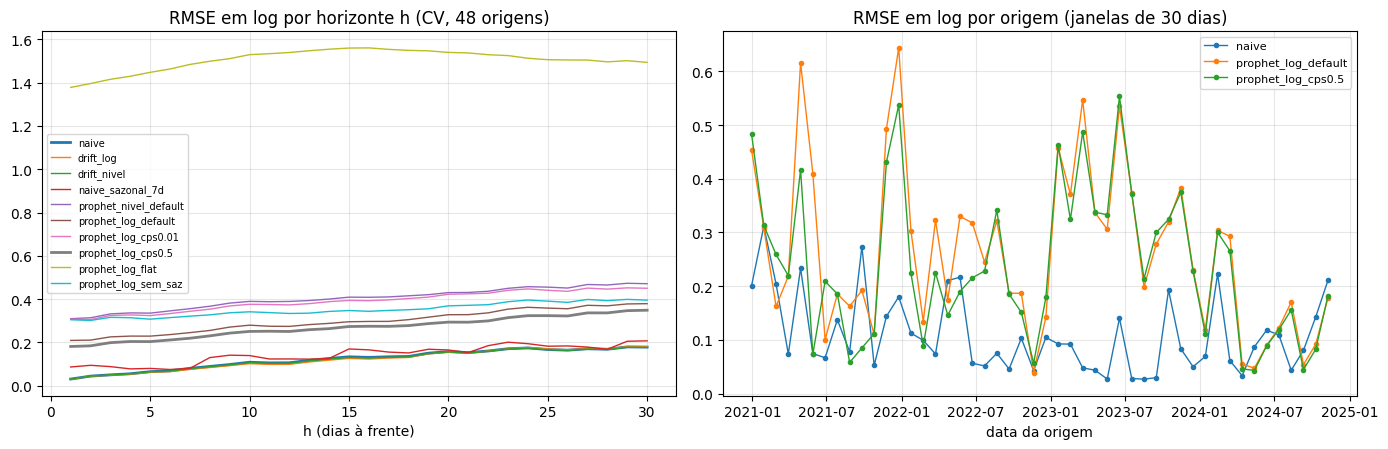

=== CV: 48 origens, treino inicial 1460, horizonte 30, passo 30 (janela expansiva, SÓ treino) ===
escala MASE_log (MAE do naive 1 passo no treino da origem): mín 0.0251 | máx 0.0287

=== TABELA A: desempenho em log, h = 1..30 ===
                       RMSE_log  RMSE_log_rel_naive  mediana_RMSE_log_por_origem  mediana_por_origem_rel_naive  MAE_log  MASE_log  viés_log  %_origens_melhor_que_naive  n_prev<=0 (truncadas)
modelo                                                                                                                                                                                        
naive                    0.1305              1.0000                       0.0852                        1.0000   0.0932    3.4154    0.0308                         NaN                      0
drift_log                0.1283              0.9836                       0.0876                        1.0291   0.0913    3.3416    0.0039                     52.0833                      0
drift_

In [20]:
# ===== ETAPA 5 · tabelas e gráficos (horizonte CV_HORIZON; NÃO comparável ao horizonte H_TEST da Etapa 4) =====
cv["abs_e"], cv["sq_e"] = cv["e_log"].abs(), cv["e_log"] ** 2
cv["mase_t"] = cv["abs_e"] / cv["escala"]
ordem5 = ["naive", "drift_log", "drift_nivel", "naive_sazonal_7d"] + list(VARIANTES)
g = cv.groupby("modelo")
tabA = pd.DataFrame({"RMSE_log": np.sqrt(g["sq_e"].mean()), "MAE_log": g["abs_e"].mean(),
                     "MASE_log": g["mase_t"].mean(), "viés_log": g["e_log"].mean()}).loc[ordem5]
tabA["RMSE_log_rel_naive"] = tabA["RMSE_log"] / tabA.loc["naive", "RMSE_log"]       # <1: melhor que o naive

# RMSE por origem (cada janela de previsão): mostra se o resultado é estável ou concentrado em poucos períodos
po = (cv.groupby(["modelo", "t0"])["sq_e"].mean() ** .5).unstack("modelo")[ordem5]
tabA["mediana_RMSE_log_por_origem"] = po.median()
tabA["%_origens_melhor_que_naive"] = [100 * float((po[m] < po["naive"]).mean()) if m != "naive" else np.nan for m in ordem5]
tabA["n_prev<=0 (truncadas)"] = [nao_pos.get(m, 0) for m in ordem5]

# Agregado e mediana por origem lado a lado, ambas relativas ao naive
tabA["mediana_por_origem_rel_naive"] = tabA["mediana_RMSE_log_por_origem"] / tabA.loc["naive", "mediana_RMSE_log_por_origem"]
tabA = tabA[["RMSE_log", "RMSE_log_rel_naive", "mediana_RMSE_log_por_origem", "mediana_por_origem_rel_naive", "MAE_log",
             "MASE_log", "viés_log", "%_origens_melhor_que_naive", "n_prev<=0 (truncadas)"]]

# Candidato pela regra FIXADA DE ANTEMÃO: menor RMSE_log entre as variantes do Prophet (só dentro do treino)
candidato = tabA.loc[list(VARIANTES), "RMSE_log"].idxmin()

faixas5 = [(0, 7), (7, 14), (14, CV_HORIZON)]
cv["faixa"] = pd.cut(cv["h"], bins=[0, 7, 14, CV_HORIZON], labels=[f"h {a + 1}-{b}" for a, b in faixas5])
tabB = (cv.groupby(["modelo", "faixa"], observed=True)["sq_e"].mean() ** .5).unstack("faixa").loc[ordem5]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
rh = (cv.groupby(["modelo", "h"])["sq_e"].mean() ** .5).unstack("modelo")
for m in ordem5: ax[0].plot(rh.index, rh[m], lw=2 if m in ("naive", candidato) else 1, label=m)
ax[0].set_title(f"RMSE em log por horizonte h (CV, {len(origens)} origens)"); ax[0].set_xlabel("h (dias à frente)"); ax[0].legend(fontsize=7)
datas_o = [cv_serie.index[t0 - 1] for t0 in po.index]
for m in dict.fromkeys(["naive", "prophet_log_default", candidato]): ax[1].plot(datas_o, po[m].values, marker="o", ms=3, lw=1, label=m)
ax[1].set_title(f"RMSE em log por origem (janelas de {CV_HORIZON} dias)"); ax[1].set_xlabel("data da origem"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"=== CV: {len(origens)} origens, treino inicial {CV_INITIAL}, horizonte {CV_HORIZON}, passo {CV_STEP} (janela expansiva, SÓ treino) ===")
print(f"escala MASE_log (MAE do naive 1 passo no treino da origem): mín {min(escala_o.values()):.4f} | máx {max(escala_o.values()):.4f}")
print("\n=== TABELA A: desempenho em log, h = 1..%d ===" % CV_HORIZON)
print(tabA.to_string(float_format=lambda v: f"{v:.4f}"))
print("\n=== TABELA B: RMSE em log por faixa de horizonte ===")
print(tabB.to_string(float_format=lambda v: f"{v:.4f}"))
print(f"\nCandidato do Prophet pela regra pré-fixada (menor RMSE_log na CV): {candidato}")
print(f"Candidato fixado em CANDIDATO_PROPHET (Célula 1): {CANDIDATO_PROPHET} | coincide com a regra da CV: {candidato == CANDIDATO_PROPHET}")
# o candidato está na borda da grade de changepoint_prior_scale?
grade_cps = {n: c["kw"].get("changepoint_prior_scale", 0.05) for n, c in VARIANTES.items()
             if c["log"] and set(c["kw"]) <= {"changepoint_prior_scale"}}
if candidato in grade_cps and grade_cps[candidato] in (min(grade_cps.values()), max(grade_cps.values())):
    print(f"ATENÇÃO: o candidato tem cps={grade_cps[candidato]}, na BORDA da grade {sorted(set(grade_cps.values()))}; "
          "ampliar a grade seria uma nova busca (exploratória; regra fixada antes de olhar).")
print("(Nada aqui usa 2025.)")

Célula 20: Diebold-Mariano na CV (uma perda por origem, correção HLN)

In [21]:

# ===== ETAPA 5 · Diebold-Mariano por origem =====
from scipy import stats as sps
import statsmodels.api as sm

def dm_hln(d, h=1):
    """DM com correção de Harvey-Leybourne-Newbold. d = perda(ref) - perda(modelo), uma por origem. d > 0: modelo melhor.
    As janelas de previsão não se sobrepõem, então tratamos a sequência de origens como previsões de 1 passo (h=1)."""
    d = np.asarray(d, float); n = len(d)
    dm = d.mean() / np.sqrt(np.var(d, ddof=0) / n)                        # variância de longo prazo ≈ γ0 (h=1)
    stat = np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n) * dm             # fator HLN
    return float(d.mean()), float(stat), float(2 * sps.t.sf(abs(stat), n - 1))   # p-valor da t(n-1), bilateral

def holm(p):
    p = np.asarray(p, float); m = len(p); adj = np.empty(m); run = 0.0
    for rank, idx in enumerate(np.argsort(p)):
        run = max(run, (m - rank) * p[idx]); adj[idx] = min(1.0, run)
    return adj

def dm_tabela(df, pares, perda="sq"):
    """df longo (modelo, t0, h, e_log). pares = [(modelo, referência)]. perda: 'sq' (erro²) ou 'abs' (|erro|), em log.
    LEITURA PRINCIPAL: DM-HLN (p_HLN) + Holm. O p HAC é só sensibilidade (liberal com poucas origens)."""
    L = df.assign(L=df["e_log"] ** 2 if perda == "sq" else df["e_log"].abs())
    L_or = L.groupby(["modelo", "t0"])["L"].mean().unstack("modelo")                                    # 1 perda por origem
    L_hs = L.sort_values(["t0", "h"]).pivot(index=["t0", "h"], columns="modelo", values="L")            # perda diária, ordem temporal
    col_hac = "p_HAC_sens(lag=%d)" % (CV_HORIZON - 1)
    linhas = []
    for m, ref in pares:
        d = (L_or[ref] - L_or[m]).values
        dbar, stat, p = dm_hln(d)
        dh = (L_hs[ref] - L_hs[m]).values
        hac = sm.OLS(dh, np.ones(len(dh))).fit(cov_type="HAC", cov_kwds={"maxlags": CV_HORIZON - 1})
        # autocorrelação de d só é calculada com n >= 20: com n pequeno (ex.: 12 origens = 11 pares) não tem valor informativo
        ac = float(np.corrcoef(d[:-1], d[1:])[0, 1]) if len(d) >= 20 else np.nan
        linhas.append({"modelo": m, "referência": ref, "n_origens": len(d), "dif_média(ref-modelo)": dbar,
                       "DM_HLN": stat, "p_HLN": p, "%origens_modelo_melhor": 100 * float(np.mean(d > 0)),
                       "autocorr_lag1_de_d": ac, col_hac: float(hac.pvalues[0])})
    t = pd.DataFrame(linhas)
    fam = (t["referência"] == "naive").values
    t["p_Holm(vs naive)"], t["p_Holm(pares diretos)"] = np.nan, np.nan
    if fam.any():   t.loc[fam, "p_Holm(vs naive)"] = holm(t.loc[fam, "p_HLN"].values)
    if (~fam).any(): t.loc[~fam, "p_Holm(pares diretos)"] = holm(t.loc[~fam, "p_HLN"].values)
    t["aviso"] = np.where(t["autocorr_lag1_de_d"].abs() > 0.4, "d autocorrelacionado: p subestimado (DM h=1 supõe independência)", "")
    return t[["modelo", "referência", "n_origens", "dif_média(ref-modelo)", "DM_HLN", "p_HLN", "p_Holm(vs naive)",
              "p_Holm(pares diretos)", "%origens_modelo_melhor", "autocorr_lag1_de_d", col_hac, "aviso"]]

# Pares: cada modelo vs. naive (família corrigida por Holm) + duas comparações diretas pré-definidas (Holm próprio, 2 pares)
pares_cv = [(m, "naive") for m in ordem5 if m != "naive"] + [("prophet_log_default", "prophet_log_sem_saz"),
                                                              (CANDIDATO_PROPHET, "prophet_log_default")]
fmt = lambda v: f"{v:.4g}"
print("=== DIEBOLD-MARIANO NA CV · perda = erro² em log · uma perda por origem ===")
print("LEITURA PRINCIPAL: DM_HLN, p_HLN e Holm. dif > 0 e DM > 0: o modelo foi MELHOR que a referência. n efetivo ≈ nº de origens, não 1440.")
print("p_HAC é só sensibilidade (tende a ser liberal com poucas origens). O p da comparação direta do candidato contra o default na CV é OTIMISTA (viés de seleção).")
dm_cv_sq = dm_tabela(cv, pares_cv, "sq"); print(dm_cv_sq.to_string(index=False, float_format=fmt))
print("\n=== DIEBOLD-MARIANO NA CV · perda = |erro| em log (sensibilidade) ===")
dm_cv_abs = dm_tabela(cv, pares_cv, "abs"); print(dm_cv_abs.to_string(index=False, float_format=fmt))


=== DIEBOLD-MARIANO NA CV · perda = erro² em log · uma perda por origem ===
LEITURA PRINCIPAL: DM_HLN, p_HLN e Holm. dif > 0 e DM > 0: o modelo foi MELHOR que a referência. n efetivo ≈ nº de origens, não 1440.
p_HAC é só sensibilidade (tende a ser liberal com poucas origens). O p da comparação direta do candidato contra o default na CV é OTIMISTA (viés de seleção).
               modelo          referência  n_origens  dif_média(ref-modelo)  DM_HLN     p_HLN  p_Holm(vs naive)  p_Holm(pares diretos)  %origens_modelo_melhor  autocorr_lag1_de_d  p_HAC_sens(lag=29)                                                            aviso
            drift_log               naive         48              0.0005524  0.4658    0.6435            0.6435                    NaN                   52.08              0.2614              0.6087                                                                 
          drift_nivel               naive         48                0.00036   1.168    0.2485           

# Etapa 6: avaliação no teste (uso formal, com lista fixada)

**Pré-especificação.** Os modelos avaliados são **exatamente** os de `MODELOS_TESTE` (Célula 1), fixados antes de rodar esta etapa: 4 benchmarks (naive, drift em log, drift em nível, naive sazonal de 7 dias), o Prophet com defaults (em nível e em log) e **um** candidato do Prophet, escolhido pela regra da CV (menor RMSE em log, só no treino). Nenhum modelo, variante ou hiperparâmetro entra ou muda depois de ver estes resultados.

**Transparência.** O teste é visto pela segunda vez (a primeira foi na Etapa 4) e a lista de variantes da CV foi definida depois da Etapa 4. Isto deve ser declarado no seminário. Se a Célula 21 acusar que o candidato fixado não coincide com a regra da CV, ela **para**.

**Duas avaliações, nunca misturadas**
- **Parte A: horizonte de 30 dias, origens móveis dentro do teste** (mesmo protocolo da Etapa 5). Em cada origem o modelo usa todos os dados *até aquele dia* (inclusive os dias do teste já passados, que seriam conhecidos na vida real), prevê os 30 dias seguintes e não vê o futuro. Dá ≈ 12 janelas e permite o teste de Diebold-Mariano (Célula 20), com **baixo poder** por ter poucas origens.
- **Parte B: horizonte de 365 dias, origem única** (desenho do tutorial: treina até `TRAIN_END` e prevê todo o teste). É **uma única trajetória**: serve para mostrar o comportamento no horizonte longo, mas **não permite inferência** (não há como testar significância com uma observação). A faixa de horizonte 1–30 da Parte B é a **mesma origem e o mesmo modelo** da 1ª janela da Parte A (ajuste determinístico): **não é evidência independente** e não deve ser apresentada como tal.

**O que cada gráfico mostra e por que importa**
- *RMSE em log por origem (Parte A)*: se o resultado é estável nas ~12 janelas ou concentrado em poucas. Importa porque a média pode esconder um único episódio.
- *RMSE em log por horizonte (Parte A)*: como o erro cresce de 1 a 30 dias.
- *Trajetórias de 365 dias em escala log (Parte B)*: mostra se a previsão é plausível (a escala log evita que um modelo explosivo esconda os outros).
- *|erro em log| por horizonte (Parte B)*: como o erro acumula em um ano.

**Como ler.**
- O teste não escolhe modelo: só mede. Qualquer comparação de erro médio sem o DM é descritiva. Não se tira conclusão de previsibilidade com ~12 origens ou uma trajetória.
- **Estatística principal: DM-HLN com Holm.** O p HAC diário é só sensibilidade: com ~12 blocos de 30 dias e defasagem 29 ele tende a ser mais liberal que o HLN. O código imprime quantas comparações Prophet vs. naive têm p Holm < α no teste.
- **Generalização da seleção.** O candidato foi escolhido por ter o menor RMSE entre várias variantes na CV; o p dele na CV é otimista (viés de seleção). A tabela "generalização da seleção" coloca CV e teste lado a lado: se a vantagem da CV desaparece no teste, a seleção não generalizou, e o seminário deve dizer isso.

Célula 21: previsões no teste (Parte A: 30 dias, origens móveis; Parte B: 365 dias, origem única)

In [22]:
# ===== ETAPA 6 · previsões no TESTE (lista fixada em MODELOS_TESTE) =====
# TRANSPARÊNCIA: o teste já foi visto na Etapa 4 e é visto de novo aqui. Nenhum modelo/variante/hiperparâmetro novo entra.
import logging
from prophet import Prophet
logging.getLogger("cmdstanpy").setLevel(logging.WARNING); logging.getLogger("prophet").setLevel(logging.WARNING)

assert CANDIDATO_PROPHET in MODELOS_TESTE and all(m in ordem5 for m in MODELOS_TESTE), "MODELOS_TESTE inconsistente"
assert CANDIDATO_PROPHET == candidato, (f"o candidato fixado ({CANDIDATO_PROPHET}) NÃO coincide com a regra da CV ({candidato}). "
                                        "Não rode a Etapa 6 sem resolver isso com o revisor (nada pode ser escolhido pelo teste).")
serie_full = pd.concat([train, test])
y_full = serie_full.values.astype(float); ly_full = np.log(y_full); n_tr, n_all = len(train), len(serie_full)
assert n_all == n_total and n_tr + H_TEST == n_all

def log_prot6(yhat):
    yhat = np.asarray(yhat, float); return np.log(np.maximum(yhat, 1.0)), int((yhat <= 0).sum())

def prevê_log(modelo, t0, H):
    """Previsão em LOG de H dias a partir da origem t0, usando SÓ y_full[:t0] (nada do futuro). Retorna (previsão, nº de valores <= 0)."""
    assert t0 >= n_tr
    y_tr, ly_tr = y_full[:t0], ly_full[:t0]; h = np.arange(1, H + 1)
    if modelo == "naive":            return np.full(H, ly_tr[-1]), 0
    if modelo == "drift_log":        return ly_tr[-1] + h * (ly_tr[-1] - ly_tr[0]) / (t0 - 1), 0
    if modelo == "drift_nivel":      return log_prot6(y_tr[-1] + (y_tr[-1] - y_tr[0]) / (t0 - 1) * h)
    if modelo == "naive_sazonal_7d": return log_prot6(np.tile(y_tr[-7:], int(np.ceil(H / 7)))[:H])
    cfg = VARIANTES[modelo]                                                   # especificações EXATAS da Etapa 5
    d = pd.DataFrame({"ds": serie_full.index[:t0], "y": ly_tr if cfg["log"] else y_tr})
    reseed(); m = Prophet(uncertainty_samples=0, **cfg["kw"]); m.fit(d)
    reseed(); yh = m.predict(pd.DataFrame({"ds": serie_full.index[t0:t0 + H]}))["yhat"].values
    return (yh, 0) if cfg["log"] else log_prot6(yh)

# ---- Parte A: origens móveis de CV_STEP dias DENTRO do teste, horizonte CV_HORIZON ----
origens_te = list(range(n_tr, n_all - CV_HORIZON + 1, CV_STEP))
if CV_MAX_ORIGENS is not None: origens_te = origens_te[:CV_MAX_ORIGENS]
nao_pos6, blocos_a = {m: 0 for m in MODELOS_TESTE}, []
for m in MODELOS_TESTE:
    for t0 in origens_te:
        lyh, nb = prevê_log(m, t0, CV_HORIZON); nao_pos6[m] += nb
        blocos_a.append(pd.DataFrame({"modelo": m, "t0": t0, "origem": serie_full.index[t0 - 1], "h": np.arange(1, CV_HORIZON + 1),
                                      "ly": ly_full[t0:t0 + CV_HORIZON], "lyhat": lyh,
                                      "escala": float(np.mean(np.abs(np.diff(ly_full[:t0]))))}))
te30 = pd.concat(blocos_a, ignore_index=True); te30["e_log"] = te30["ly"] - te30["lyhat"]
te30.to_csv("teste_origem_movel_30d.csv", index=False)

# ---- Parte B: origem única em TRAIN_END, horizonte H_TEST ----
prev365, nao_pos365 = {}, {}
for m in MODELOS_TESTE: prev365[m], nao_pos365[m] = prevê_log(m, n_tr, H_TEST)
ly_te = ly_full[n_tr:]
print(f"Parte A: {len(origens_te)} origens | primeira: {serie_full.index[origens_te[0] - 1].date()} | última: {serie_full.index[origens_te[-1] - 1].date()} "
      f"| dias finais do teste sem janela completa: {n_all - (origens_te[-1] + CV_HORIZON)}")
print(f"Parte B: origem {TRAIN_END.date()} | horizonte {H_TEST} dias")
# Conferência com a Etapa 4 (mesmas especificações; só muda uncertainty_samples=0, que não altera o yhat)
for novo, velho in {"prophet_nivel_default": "prophet_nivel", "prophet_log_default": "prophet_log"}.items():
    if novo in prev365:
        print(f"conferência {novo} vs Etapa 4 ({velho}): maior diferença relativa = {np.max(np.abs(np.exp(prev365[novo]) / prev[velho] - 1)):.2e}")

Parte A: 12 origens | primeira: 2024-12-31 | última: 2025-11-26 | dias finais do teste sem janela completa: 5
Parte B: origem 2024-12-31 | horizonte 365 dias
conferência prophet_nivel_default vs Etapa 4 (prophet_nivel): maior diferença relativa = 8.88e-16
conferência prophet_log_default vs Etapa 4 (prophet_log): maior diferença relativa = 0.00e+00


Célula 22: tabelas-resumo da Etapa 6, Parte A (30 dias, origens móveis no teste) (cole aqui)

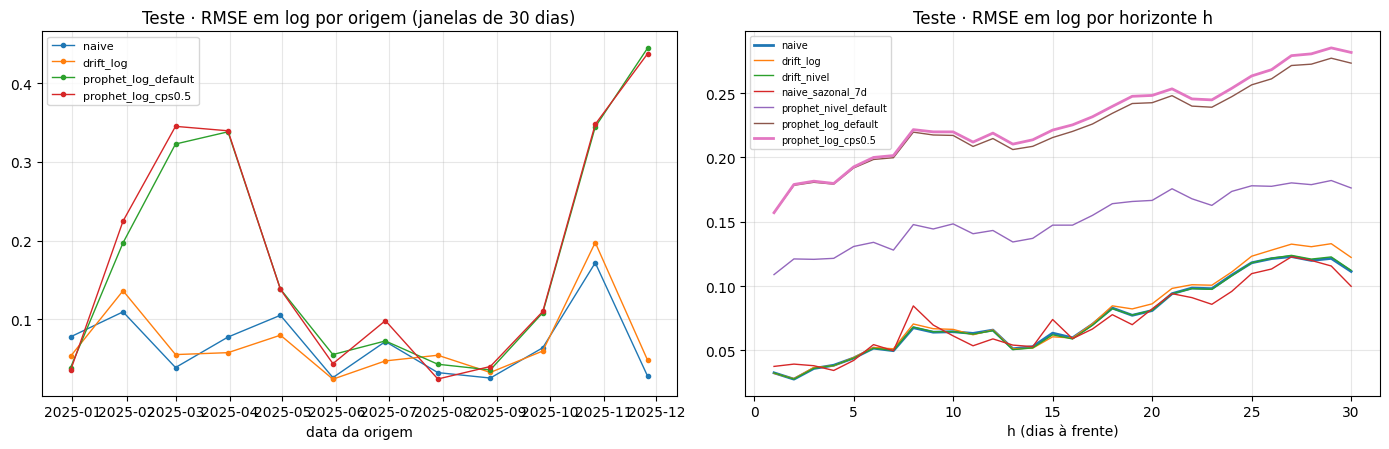

=== TESTE · PARTE A: 12 origens móveis, horizonte 30 d (NÃO comparável à Parte B de 365 d) ===
                       RMSE_log  RMSE_log_rel_naive  mediana_RMSE_log_por_origem  mediana_por_origem_rel_naive  MAE_log  MASE_log  viés_log  %_origens_melhor_que_naive  n_prev<=0 (truncadas)
modelo                                                                                                                                                                                        
naive                    0.0807              1.0000                       0.0677                        1.0000   0.0580    2.3586    0.0027                         NaN                      0
drift_log                0.0845              1.0462                       0.0546                        0.8070   0.0593    2.4140   -0.0205                     50.0000                      0
drift_nivel              0.0808              1.0004                       0.0641                        0.9476   0.0576    2.3404   -0.0022  

In [23]:
# ===== ETAPA 6 · Parte A: horizonte CV_HORIZON, origens móveis DENTRO do teste =====
te30["abs_e"], te30["sq_e"], te30["mase_t"] = te30["e_log"].abs(), te30["e_log"] ** 2, te30["e_log"].abs() / te30["escala"]
g6 = te30.groupby("modelo")
tab6A = pd.DataFrame({"RMSE_log": np.sqrt(g6["sq_e"].mean()), "MAE_log": g6["abs_e"].mean(),
                      "MASE_log": g6["mase_t"].mean(), "viés_log": g6["e_log"].mean()}).loc[MODELOS_TESTE]
po6 = (te30.groupby(["modelo", "t0"])["sq_e"].mean() ** .5).unstack("modelo")[MODELOS_TESTE]
tab6A["RMSE_log_rel_naive"] = tab6A["RMSE_log"] / tab6A.loc["naive", "RMSE_log"]
tab6A["mediana_RMSE_log_por_origem"] = po6.median()
tab6A["mediana_por_origem_rel_naive"] = po6.median() / po6.median()["naive"]
tab6A["%_origens_melhor_que_naive"] = [100 * float((po6[m] < po6["naive"]).mean()) if m != "naive" else np.nan for m in MODELOS_TESTE]
tab6A["n_prev<=0 (truncadas)"] = [nao_pos6[m] for m in MODELOS_TESTE]
tab6A = tab6A[["RMSE_log", "RMSE_log_rel_naive", "mediana_RMSE_log_por_origem", "mediana_por_origem_rel_naive", "MAE_log",
               "MASE_log", "viés_log", "%_origens_melhor_que_naive", "n_prev<=0 (truncadas)"]]
tab6B = (te30.assign(faixa=pd.cut(te30["h"], bins=[0, 7, 14, CV_HORIZON], labels=["h 1-7", "h 8-14", f"h 15-{CV_HORIZON}"]))
         .groupby(["modelo", "faixa"], observed=True)["sq_e"].mean().pow(.5).unstack("faixa").loc[MODELOS_TESTE])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
datas6 = [serie_full.index[t0 - 1] for t0 in po6.index]
for m in dict.fromkeys(["naive", "drift_log", "prophet_log_default", CANDIDATO_PROPHET]):
    ax[0].plot(datas6, po6[m].values, marker="o", ms=3, lw=1, label=m)
ax[0].set_title(f"Teste · RMSE em log por origem (janelas de {CV_HORIZON} dias)"); ax[0].set_xlabel("data da origem"); ax[0].legend(fontsize=8)
rh6 = (te30.groupby(["modelo", "h"])["sq_e"].mean() ** .5).unstack("modelo")
for m in MODELOS_TESTE: ax[1].plot(rh6.index, rh6[m], lw=2 if m in ("naive", CANDIDATO_PROPHET) else 1, label=m)
ax[1].set_title("Teste · RMSE em log por horizonte h"); ax[1].set_xlabel("h (dias à frente)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"=== TESTE · PARTE A: {len(origens_te)} origens móveis, horizonte {CV_HORIZON} d (NÃO comparável à Parte B de {H_TEST} d) ===")
print(tab6A.to_string(float_format=lambda v: f"{v:.4f}"))
print("\n=== PARTE A: RMSE em log por faixa de horizonte ===");  print(tab6B.to_string(float_format=lambda v: f"{v:.4f}"))
print("\n=== RMSE_log relativo ao naive: CV (treino) vs. teste, mesmo horizonte de %d d ===" % CV_HORIZON)
print(pd.DataFrame({"CV (treino)": tabA["RMSE_log_rel_naive"], "teste (Parte A)": tab6A["RMSE_log_rel_naive"]}).loc[MODELOS_TESTE].to_string(float_format=lambda v: f"{v:.4f}"))

pares6 = [(m, "naive") for m in MODELOS_TESTE if m != "naive"] + [(CANDIDATO_PROPHET, "prophet_log_default")]
print("\n=== DIEBOLD-MARIANO NO TESTE · erro² em log · uma perda por origem, HLN (poucas origens: BAIXO PODER) ===")
dm_te_sq = dm_tabela(te30, pares6, "sq"); print(dm_te_sq.to_string(index=False, float_format=fmt))
print("\n=== DIEBOLD-MARIANO NO TESTE · |erro| em log (sensibilidade) ===")
dm_te_abs = dm_tabela(te30, pares6, "abs"); print(dm_te_abs.to_string(index=False, float_format=fmt))
# ---- Leitura principal = DM-HLN + Holm; HAC é só sensibilidade ----
fam_te = dm_te_sq[(dm_te_sq["referência"] == "naive") & dm_te_sq["modelo"].str.startswith("prophet")]
print(f"\nPRINCIPAL (HLN + Holm, erro²): {int((fam_te['p_Holm(vs naive)'] < ALPHA).sum())} de {len(fam_te)} comparações Prophet vs. naive "
      f"com p Holm < {ALPHA} no teste. (O p HAC diário é só sensibilidade: com poucas origens tende a ser mais liberal.)")

# ---- A seleção do candidato generalizou? CV (treino) vs. teste ----
def _linha(dm, nome_cand=CANDIDATO_PROPHET, ref="prophet_log_default"):
    return dm[(dm["modelo"] == nome_cand) & (dm["referência"] == ref)].iloc[0]
c_cv, c_te = _linha(dm_cv_sq), _linha(dm_te_sq)
tab_gen = pd.DataFrame({
    "CV (treino)":     {"n_origens": c_cv["n_origens"], "dif_média(default - candidato)": c_cv["dif_média(ref-modelo)"], "DM_HLN": c_cv["DM_HLN"],
                        "p_HLN": c_cv["p_HLN"], "p_Holm(pares diretos)": c_cv["p_Holm(pares diretos)"],
                        "%origens candidato melhor": c_cv["%origens_modelo_melhor"],
                        "RMSE_log_rel_naive (candidato)": tabA.loc[CANDIDATO_PROPHET, "RMSE_log_rel_naive"],
                        "RMSE_log_rel_naive (default)": tabA.loc["prophet_log_default", "RMSE_log_rel_naive"]},
    "teste (Parte A)": {"n_origens": c_te["n_origens"], "dif_média(default - candidato)": c_te["dif_média(ref-modelo)"], "DM_HLN": c_te["DM_HLN"],
                        "p_HLN": c_te["p_HLN"], "p_Holm(pares diretos)": c_te["p_Holm(pares diretos)"],
                        "%origens candidato melhor": c_te["%origens_modelo_melhor"],
                        "RMSE_log_rel_naive (candidato)": tab6A.loc[CANDIDATO_PROPHET, "RMSE_log_rel_naive"],
                        "RMSE_log_rel_naive (default)": tab6A.loc["prophet_log_default", "RMSE_log_rel_naive"]}})
print(f"\n=== GENERALIZAÇÃO DA SELEÇÃO: {CANDIDATO_PROPHET} vs. prophet_log_default (erro² em log) ===")
print(f"O p da CV é OTIMISTA: o candidato foi o menor RMSE entre {len(VARIANTES)} variantes (viés de seleção) e essa comparação direta está fora da família Holm do naive.")
print(tab_gen.to_string(float_format=lambda v: f"{v:.4g}"))


Célula 23: tabelas-resumo da Etapa 6, Parte B (365 dias, origem única; sem inferência) (cole aqui)

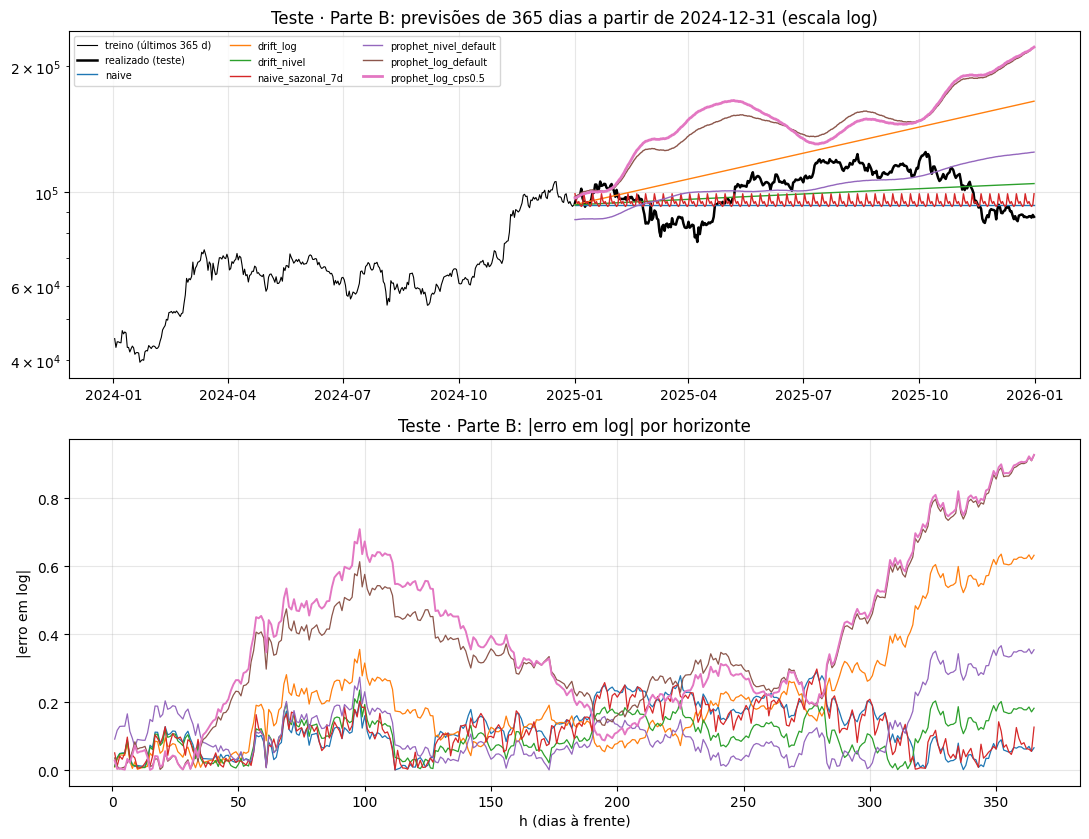

=== TESTE · PARTE B: origem única, horizonte 365 d (UMA trajetória; sem inferência; NÃO comparável à Parte A) ===
                       RMSE_log  RMSE_log_rel_naive  MAE_log  MASE_log  viés_log    RMSE_US$  n_prev<=0 (truncadas)  razão_final/inicial_prevista
naive                    0.1407              1.0000   0.1211    4.8347    0.0774 14,325.7379                 0.0000                        1.0000
drift_log                0.2709              1.9247   0.2147    8.5692   -0.2069 32,154.1138                 0.0000                        1.7605
drift_nivel              0.1146              0.8144   0.1013    4.0443    0.0179 11,560.5307                 0.0000                        1.1232
naive_sazonal_7d         0.1346              0.9561   0.1162    4.6394    0.0623 13,690.3597                 0.0000                        1.0000
prophet_nivel_default    0.1503              1.0679   0.1195    4.7695   -0.0267 15,365.2887                 0.0000                        1.4466
prophet_lo

In [24]:
# ===== ETAPA 6 · Parte B: horizonte H_TEST, origem única (UMA trajetória: descritivo, sem inferência) =====
escala_B = float(np.mean(np.abs(np.diff(ly_full[:n_tr]))))        # MASE em log: naive de 1 passo no treino
def met_B(m):
    e = ly_te - prev365[m]; eus = y_full[n_tr:] - np.exp(prev365[m])
    return {"RMSE_log": float(np.sqrt(np.mean(e ** 2))), "MAE_log": float(np.mean(np.abs(e))), "MASE_log": float(np.mean(np.abs(e)) / escala_B),
            "viés_log": float(np.mean(e)), "RMSE_US$": float(np.sqrt(np.mean(eus ** 2))), "n_prev<=0 (truncadas)": nao_pos365[m]}
tab6C = pd.DataFrame({m: met_B(m) for m in MODELOS_TESTE}).T
tab6C.insert(1, "RMSE_log_rel_naive", tab6C["RMSE_log"] / tab6C.loc["naive", "RMSE_log"])
tab6C["razão_final/inicial_prevista"] = [float(np.exp(prev365[m][-1] - prev365[m][0])) for m in MODELOS_TESTE]
borB = [b for b in sorted({0, CV_HORIZON, 90, H_TEST}) if b <= H_TEST]
tab6D = pd.DataFrame({f"h {a + 1}-{b}": {m: float(np.sqrt(np.mean((ly_te[a:b] - prev365[m][a:b]) ** 2))) for m in MODELOS_TESTE}
                      for a, b in zip(borB[:-1], borB[1:])})

fig, ax = plt.subplots(2, 1, figsize=(11, 8.5))
ax[0].plot(train.index[-H_TEST:], train.values[-H_TEST:], c="k", lw=.8, label=f"treino (últimos {H_TEST} d)")
ax[0].plot(test.index, test.values, c="k", lw=1.8, label="realizado (teste)")
for m in MODELOS_TESTE: ax[0].plot(test.index, np.exp(prev365[m]), lw=2 if m == CANDIDATO_PROPHET else 1, label=m)
ax[0].set_yscale("log"); ax[0].set_title(f"Teste · Parte B: previsões de {H_TEST} dias a partir de {TRAIN_END.date()} (escala log)"); ax[0].legend(ncol=3, fontsize=7)
hh = np.arange(1, H_TEST + 1)
for m in MODELOS_TESTE: ax[1].plot(hh, np.abs(ly_te - prev365[m]), lw=1.4 if m == CANDIDATO_PROPHET else .9, label=m)
ax[1].set_title("Teste · Parte B: |erro em log| por horizonte"); ax[1].set_xlabel("h (dias à frente)"); ax[1].set_ylabel("|erro em log|")
plt.tight_layout(); plt.show()

print(f"=== TESTE · PARTE B: origem única, horizonte {H_TEST} d (UMA trajetória; sem inferência; NÃO comparável à Parte A) ===")
print(tab6C.to_string(float_format=lambda v: f"{v:,.4f}"))
print(f"\n=== PARTE B: RMSE em log por faixa de horizonte (a faixa h 1-{CV_HORIZON} é a MESMA origem e o MESMO modelo da 1ª janela da Parte A: NÃO é evidência independente) ===")
print(tab6D.to_string(float_format=lambda v: f"{v:.4f}"))
# conferência: faixa inicial da Parte B == 1ª origem da Parte A (ajuste determinístico)
_pb = tab6D.iloc[:, 0]; _pa = po6.loc[n_tr, MODELOS_TESTE]
print(f"conferência: maior |diferença| entre a faixa h 1-{CV_HORIZON} da Parte B e a 1ª origem da Parte A = {float(np.max(np.abs(_pb.values - _pa.values))):.2e}")

# Etapa 7: resíduos in-sample e intervalos de previsão

## Parte A · resíduos in-sample (só no treino)

**Regra.** Os resíduos vêm do ajuste em **todo o treino** (até `TRAIN_END`) e **nunca** do teste. Modelos: os Prophet de `MODELOS_TESTE` (nível com defaults, log com defaults e o candidato). Como referência entra o "resíduo do naive", que é o retorno logarítmico diário (o naive prevê o último valor, então seu erro de 1 passo é o retorno).

**O que é o resíduo in-sample.** e_t = y_t − ŷ_t, onde ŷ_t é o valor que o Prophet ajusta para o dia *t* do treino (tendência + sazonalidades). Nos modelos em log, e_t está em log (≈ erro percentual); no modelo em nível, em US$. O modelo já "viu" y_t ao ajustar, então o resíduo in-sample é **otimista** como medida de erro de previsão: ele serve para diagnosticar estrutura que sobrou, não substitui a CV.

**Por que olhar os resíduos.** Se o modelo capturasse a estrutura, o resíduo pareceria ruído branco: média ≈ 0, sem autocorrelação, variância constante. O Prophet não modela autocorrelação nem variância que muda no tempo, então é esperado que sobre estrutura; os testes medem quanto.

**Ljung-Box e KPSS: o que cada um testa (e uma correção importante).**
- **Ljung-Box**: H0 = os resíduos **não têm autocorrelação** até o lag *L* (ruído branco). Rejeitar (p pequeno) = há autocorrelação.
- **KPSS**: H0 = a série é **estacionária** (em torno de uma constante, ou de uma tendência linear, conforme `regression`). Rejeitar = há evidência de **não estacionariedade** (raiz unitária, ou nível/tendência que se move).
- **Os nulos de Ljung-Box e KPSS não são opostos.** Os dois descrevem o caso "bom" (sem autocorrelação; estacionária) e, nos dois, **rejeitar sinaliza problema**. O par de testes com hipóteses nulas realmente **opostas** é **ADF × KPSS**: o ADF tem H0 = raiz unitária (não estacionária); o KPSS tem H0 = estacionária. Por isso esses dois são lidos em conjunto (Etapa 2). Uma leitura possível (**não verificada**: o texto original do tutorial não foi acessado aqui) para a interpretação contraditória apontada no tutorial é ler "não rejeitei H0" como "está bom" sem checar qual é a H0 de cada teste.
- **Perguntas diferentes.** Ljung-Box mede dependência linear **de curto prazo** (as autocorrelações até *L*); KPSS mede o comportamento **de longo prazo** (se o nível ou a tendência se movem). Uma série pode ser estacionária e autocorrelada (ex.: AR(1) com φ = 0,5: Ljung-Box rejeita, KPSS não), ou ter autocorrelações pequenas e um nível que deriva.

| Ljung-Box (H0: sem autocorrelação) | KPSS (H0: estacionária) | Leitura mecânica |
|---|---|---|
| não rejeita | não rejeita | sem autocorrelação linear (no lag escolhido) e sem não estacionariedade detectadas; **não diz nada sobre variância** (veja o ARCH-LM) |
| rejeita | não rejeita | estacionária, mas autocorrelada (sobrou dependência linear de curto prazo) |
| não rejeita | rejeita | sem autocorrelação linear detectada, mas nível/tendência se move |
| rejeita | rejeita | autocorrelada **e** não estacionária (persistência alta ou tendência remanescente) |

Pares realmente opostos: **ADF rejeita** (indica estacionária) com **KPSS não rejeita** (estacionária) = concordam; **ADF não rejeita** e **KPSS rejeita** = ambos indicam raiz unitária; ambos rejeitam ou ambos não rejeitam = **inconclusivo** (ex.: quebra estrutural, poucos dados).

**Cuidados.** (i) O Ljung-Box padrão supõe variância constante; com efeito ARCH ele tende a rejeitar demais, por isso reportamos também o **Box-Pierce robusto** (Etapa 2). (ii) Não aplicamos o ajuste de graus de liberdade do modelo (`model_df`): o Prophet não é um ARMA, e a distribuição χ² é só aproximada. (iii) ADF e KPSS foram desenhados para séries observadas; aplicados a resíduos estimados, os valores críticos são aproximados. (iv) Com caudas pesadas e variância condicional, os p-valores dependem de momentos que podem não existir (Etapa 2): leia como evidência qualitativa. (v) **Resíduo estacionário in-sample não implica modelo adequado.** O Prophet ajusta uma tendência flexível (25 pontos de mudança por padrão) dentro da amostra, então a estacionariedade do resíduo é esperada por construção. Todos os resíduos do Prophet têm `rho1` alto (0,94 a 0,98 nesta execução), o que indica estrutura que o modelo não captou. **Não generalize a ACF no lag 40:** ela é +0,24 no modelo em nível e −0,17 e −0,27 nos modelos em log, ou seja, a "persistência até o lag 40" vale só para o nível. A meia-vida AR(1) (31, 14 e 12 dias nesta execução) é apenas um resumo de `rho1`: os resíduos **não têm forma de AR(1)** (um AR(1) com o mesmo ρ1 daria ACF(40) positiva também nos modelos em log), então ela não deve ser lida como a memória real do resíduo. "ADF e KPSS concordam: estacionária" quer dizer apenas **não há raiz unitária no resíduo**, não que o ajuste serve.

**O que cada gráfico mostra e por que importa**
- *Resíduo no tempo*: tendência ou nível remanescente e períodos de volatilidade alta. Importa porque o Prophet não modela volatilidade que muda.
- *Resíduo × ajustado*: se a dispersão depende do nível (heterocedasticidade multiplicativa; é o motivo de usar log).
- *ACF do resíduo*: autocorrelação que sobrou (ruído branco ≈ barras dentro da banda).
- *ACF do resíduo²*: agrupamento de volatilidade que o modelo ignora.

## Parte B · intervalos de previsão

**O que o Prophet calcula.** O intervalo padrão (`interval_width=0,8`, `uncertainty_samples=1000`, `mcmc_samples=0`) simula (i) incerteza da **tendência** (mudanças de inclinação futuras sorteadas a partir das observadas) e (ii) **ruído de observação gaussiano com desvio constante**, estimado no ajuste. Não inclui a incerteza dos parâmetros sazonais (isso exigiria MCMC) nem volatilidade que muda no tempo. Em modelo em **nível**, o limite inferior pode ficar negativo (falha 8 do tutorial); em modelo em **log**, `exp()` dos limites é sempre positivo. A Célula 27 registra **em que escopos e níveis** o limite inferior fica negativo e a Célula 25 registra se o valor **ajustado** in-sample do modelo em nível é ≤ 0. A falha 8 só está reproduzida onde essas tabelas mostrarem ocorrência, e deve ser relatada **com esse escopo** (modelo em nível, escopo e nível indicados), sem generalizar para outros modelos ou escopos.

**Benchmarks de intervalo (sem Prophet).** (a) *passeio aleatório gaussiano*: log P_t ± z·σ·√h, com σ o desvio dos retornos do treino da origem; (b) *passeio aleatório empírico*: quantis das variações de *h* dias do log-preço no treino da origem (sem supor normalidade). Ambos são positivos por construção.

**Os benchmarks também não são "calibrados".** Os dois passeios aleatórios usam a volatilidade do treino da origem; se a volatilidade da época avaliada for menor que essa média, os intervalos saem **largos demais** e a cobertura passa do nominal (a coluna `z_cob_vs_nominal` mede o desvio em erros-padrão). A vantagem deles sobre o Prophet está no **interval score**: com largura parecida (ou maior), o preço cai dentro do intervalo com muito mais frequência, e a penalização do interval score é bem menor; não está numa calibração perfeita. A explicação "volatilidade do treino maior que a da época avaliada" é **hipótese**: a Célula 27 imprime o desvio dos retornos por ano e no teste para conferir.

**Como avaliamos** (níveis nominais 80% e 95%): na **CV** (só treino, h ≤ 30), no **teste, Parte A** (h ≤ 30, origens móveis) e no **teste, Parte B** (365 dias, uma origem). O teste é visto aqui **de novo**: serve só de diagnóstico, nada é ajustado a partir dele.

**Glossário**
- **Cobertura empírica**: fração dos dias em que o preço real ficou dentro do intervalo. Um intervalo de 80% bem calibrado cobre ≈ 80%. Os acertos dentro de uma janela são dependentes; por isso o erro-padrão usa o **número de origens** (cobertura por origem ± EP), não o número de dias.
- **Largura (em log)**: média de log(limite superior / limite inferior), sem unidade. Intervalo mais estreito é mais informativo, mas só vale se mantiver a cobertura.
- **Razão hi/lo** = exp(largura em log): quantas vezes o limite superior é maior que o inferior (média geométrica). **Cobertura sem largura não se interpreta**: um intervalo gigante cobre quase tudo sem ser informativo. Leia sempre cobertura, razão hi/lo e interval score **juntos**.
- **z_cob_vs_nominal**: (cobertura média por origem − nível nominal) / erro-padrão por origem. Valores longe de 0 indicam descalibração (positivo: largo demais; negativo: estreito demais), medida com o número de origens, não de dias. **Com poucas origens, compare |z| com o valor crítico da t(n−1), não com 2**: ≈ 2,20 para 12 origens (teste A) e ≈ 2,01 para 48 (CV), a 5% bilateral. **Quando a cobertura encosta em 100% o erro-padrão vai a ~0 e o z explode (ex.: 17), sem significado: nesses casos cite a cobertura, não o z.**
- **Como ler o z nesta execução.** No teste A (12 origens) só o Prophet em nível tem subcobertura clara (z = −3,74 a 80% e −3,26 a 95%); as variantes em log ficam dentro do valor crítico a 80% (z = −1,41 e −1,56) e marginais a 95% (z = −2,11 e −2,19). O contraste forte está na CV (48 origens, |z| entre 5,9 e 10,6 para os Prophet).
- **Interval score** (Gneiting & Raftery), em log: largura + (2/α) × distância do real até o intervalo, quando fora (α = 1 − nível). Menor é melhor; resume calibração e nitidez numa só medida. A comparação entre interval scores é **descritiva**: não há teste de significância para ela.
- **% de limites inferiores < 0**: fração dos dias em que o limite inferior em US$ é negativo (só pode ocorrer em modelo em nível).

Célula 24: ajuste no treino completo, resíduos in-sample e testes de diagnóstico

In [25]:
# ===== ETAPA 7 · Parte A: resíduos IN-SAMPLE do ajuste no TREINO COMPLETO (nunca no teste) =====
import logging
from prophet import Prophet
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.stats.diagnostic import acorr_ljungbox
logging.getLogger("cmdstanpy").setLevel(logging.WARNING); logging.getLogger("prophet").setLevel(logging.WARNING)

MODELOS_RES = [m for m in MODELOS_TESTE if m.startswith("prophet")]
res, ajustado = {}, {}
for nome in MODELOS_RES:
    cfg = VARIANTES[nome]                                              # mesmas especificações das Etapas 5 e 6
    d = pd.DataFrame({"ds": train.index, "y": np.log(train.values.astype(float)) if cfg["log"] else train.values.astype(float)})
    assert d["ds"].max() == TRAIN_END                                  # só o treino
    reseed(); m = Prophet(uncertainty_samples=0, **cfg["kw"]); m.fit(d)
    reseed(); yhat = m.predict(d[["ds"]])["yhat"].values              # ajustado DENTRO da amostra
    res[nome] = pd.Series(d["y"].values - yhat, index=train.index, name=nome)
    ajustado[nome] = pd.Series(yhat, index=train.index, name=nome)
series_res = {"naive (retorno log)": r.rename("naive")}
series_res.update({n: res[n] for n in MODELOS_RES})
unid = {"naive (retorno log)": "log"} | {n: ("log" if VARIANTES[n]["log"] else "US$") for n in MODELOS_RES}

def diag_serie(x):
    x = pd.Series(x).dropna(); out = {}
    out["n"] = len(x); out["média"] = float(x.mean()); out["dp"] = float(x.std())
    out["assimetria"] = float(stats.skew(x)); out["curtose_exc"] = float(stats.kurtosis(x)); out["rho1"] = float(x.autocorr(1))
    # persistência: meia-vida de um AR(1) com o mesmo rho1 (dias até a autocorrelação cair à metade) e ACF no lag 40
    out["meia_vida_AR1(d)"] = float(np.log(0.5) / np.log(out["rho1"])) if 0 < out["rho1"] < 1 else np.nan
    out["ACF(40)"] = float(acf(x.values, nlags=40, fft=True)[40])
    lb = acorr_ljungbox(x, lags=[10, 20], return_df=True)
    out["LB(10) p"], out["LB(20) p"] = float(lb.loc[10, "lb_pvalue"]), float(lb.loc[20, "lb_pvalue"])
    out["BProb(20) p"] = box_pierce_robusto(x.values, 20)[1]                  # robusto a ARCH (Etapa 2)
    out["ARCH-LM(10) p"] = arch_lm_manual(x.values, 10)[1]                    # LM = nobs·R² ~ χ²(10) (Etapa 2)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        out["ADF(c) p"] = float(adfuller(x, regression="c", autolag="AIC")[1])
        out["KPSS(c) p"] = float(kpss(x, regression="c", nlags="auto")[1])
    out["JB p"] = float(stats.jarque_bera(x)[1])
    return out

tab_res = pd.DataFrame({k: diag_serie(v) for k, v in series_res.items()}).T
def _rej(c): return tab_res[c].astype(float) < ALPHA
tab_res["LB(20) rejeita"], tab_res["KPSS rejeita"], tab_res["ADF rejeita"] = _rej("LB(20) p"), _rej("KPSS(c) p"), _rej("ADF(c) p")
leit_lb = {(False, False): "sem autocorrelação linear detectada (LB lag 20)", (True, False): "estacionária, mas autocorrelada",
           (False, True): "sem autocorrelação linear, mas nível/tendência se move", (True, True): "autocorrelada e não estacionária"}
leit_adf = {(True, False): "concordam: estacionária", (False, True): "concordam: raiz unitária",
            (True, True): "inconclusivo (ambos rejeitam)", (False, False): "inconclusivo (nenhum rejeita)"}
# a leitura usa só o Ljung-Box de lag 20 e NÃO enxerga variância: acrescentamos o efeito ARCH (ARCH-LM lag 10) ao rótulo
tab_res["efeito ARCH (ARCH-LM lag 10)"] = _rej("ARCH-LM(10) p")
tab_res["leitura LB×KPSS"] = [leit_lb[(a, b)] + ("; há efeito ARCH" if arch else "")
                              for a, b, arch in zip(tab_res["LB(20) rejeita"], tab_res["KPSS rejeita"], tab_res["efeito ARCH (ARCH-LM lag 10)"])]
tab_res["leitura ADF×KPSS"] = [leit_adf[(a, b)] for a, b in zip(tab_res["ADF rejeita"], tab_res["KPSS rejeita"])]
print("Resíduos in-sample calculados no treino completo:", {k: f"{len(v)} obs, escala {unid[k]}" for k, v in series_res.items()})

Resíduos in-sample calculados no treino completo: {'naive (retorno log)': '2921 obs, escala log', 'prophet_nivel_default': '2922 obs, escala US$', 'prophet_log_default': '2922 obs, escala log', 'prophet_log_cps0.5': '2922 obs, escala log'}


Célula 25: gráficos e tabelas dos resíduos (cole aqui)

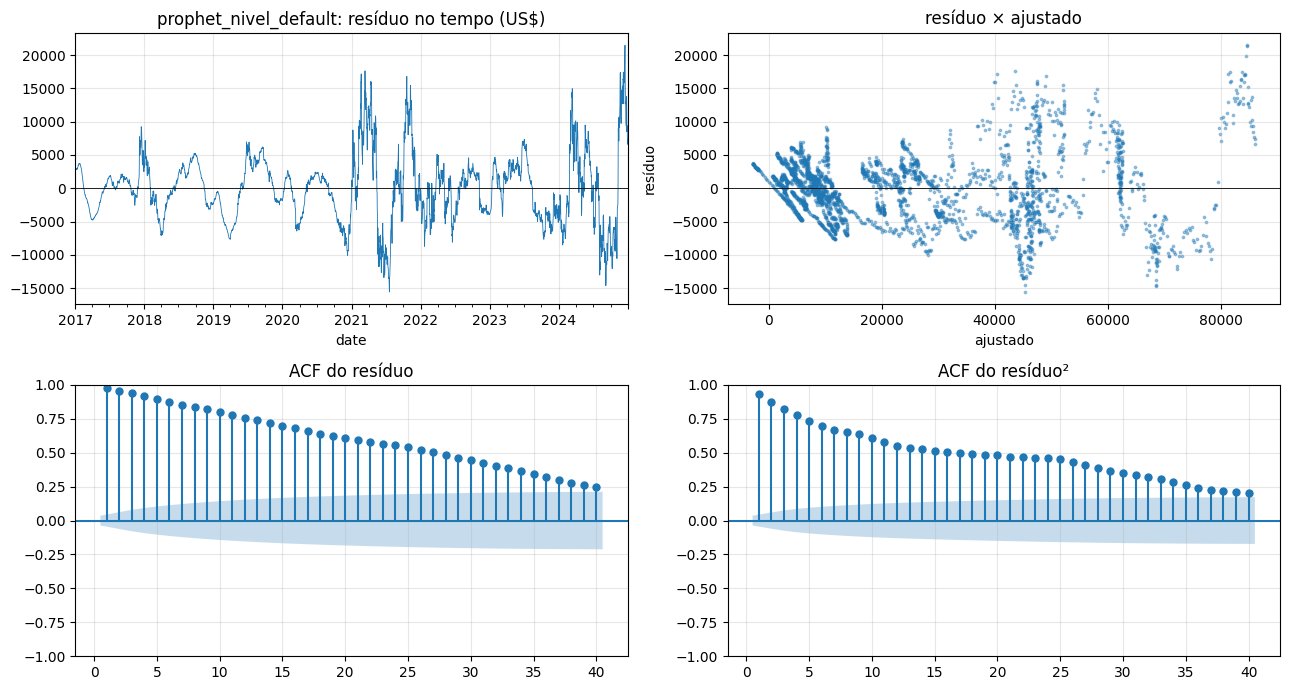

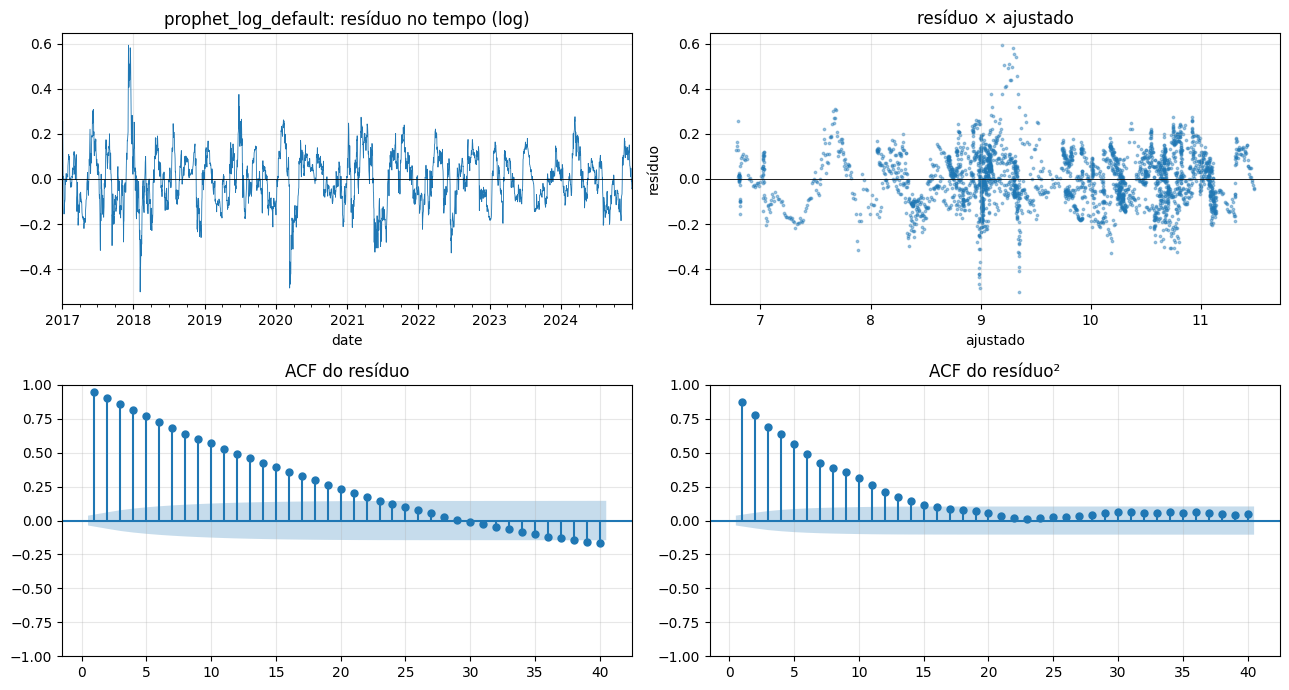

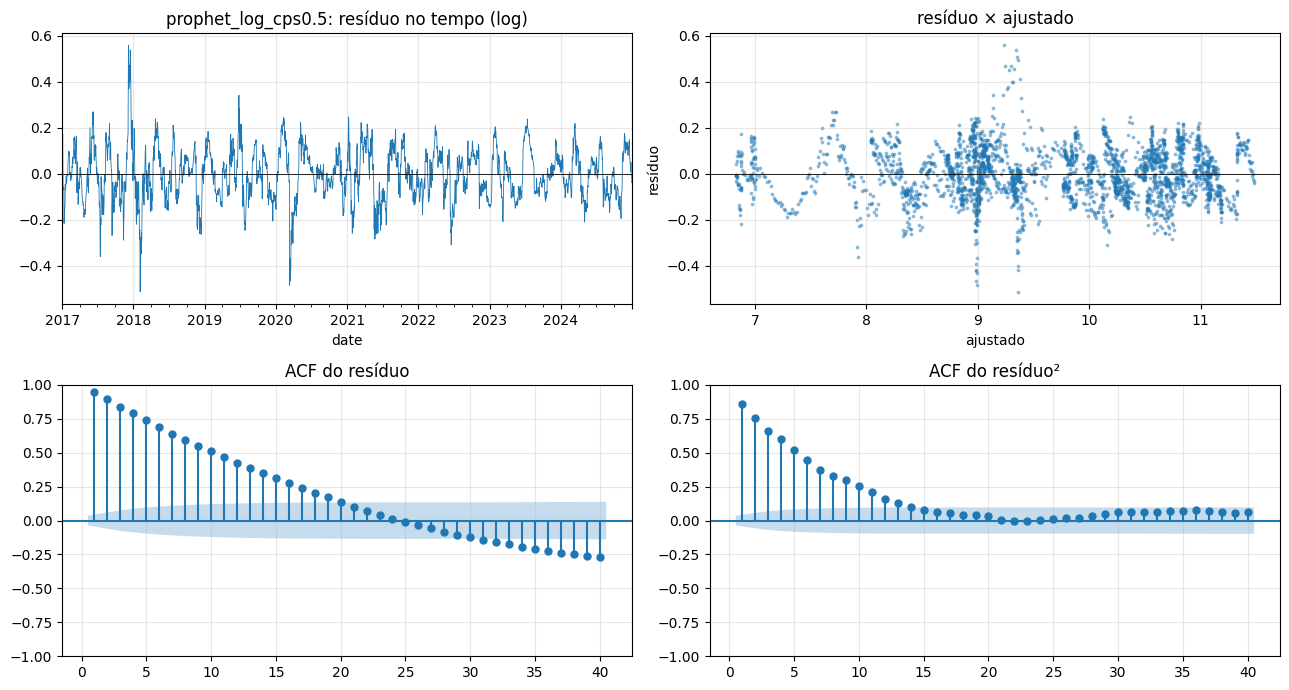

=== RESÍDUOS IN-SAMPLE (treino completo) · escalas: naive (retorno log): log, prophet_nivel_default: US$, prophet_log_default: log, prophet_log_cps0.5: log ===
                          n       média        dp assimetria curtose_exc       rho1 meia_vida_AR1(d)    ACF(40)
naive (retorno log)    2921   0.0015539  0.037696   -0.66696      11.332  -0.027413              nan  0.0032862
prophet_nivel_default  2922     0.39963    5079.8    0.42082     0.96647     0.9782           31.446    0.24455
prophet_log_default    2922  9.5427e-06   0.11869    0.11267      1.2226    0.95066             13.7   -0.16727
prophet_log_cps0.5     2922  4.4151e-06   0.11125   0.048181      1.3149    0.94383            11.99   -0.27046

=== TESTES NOS RESÍDUOS (p-valores; KPSS truncado em [0.01, 0.10]) ===
                      LB(10) p LB(20) p BProb(20) p ARCH-LM(10) p   ADF(c) p KPSS(c) p    JB p
naive (retorno log)    0.04849   0.1603      0.6312     2.385e-12     <1e-16     ≥0.10  <1e-16
prophet_nivel_defa

In [26]:
# ===== ETAPA 7 · Parte A: gráficos e tabelas =====
from statsmodels.graphics.tsaplots import plot_acf
for nome in MODELOS_RES:
    e, f = res[nome], ajustado[nome]
    fig, ax = plt.subplots(2, 2, figsize=(13, 7))
    e.plot(ax=ax[0, 0], lw=.6); ax[0, 0].axhline(0, c="k", lw=.6); ax[0, 0].set_title(f"{nome}: resíduo no tempo ({unid[nome]})")
    ax[0, 1].scatter(f.values, e.values, s=3, alpha=.4); ax[0, 1].axhline(0, c="k", lw=.6)
    ax[0, 1].set_title("resíduo × ajustado"); ax[0, 1].set_xlabel("ajustado"); ax[0, 1].set_ylabel("resíduo")
    plot_acf(e.values, lags=MAX_LAGS, ax=ax[1, 0], title="ACF do resíduo", zero=False)
    plot_acf(e.values ** 2, lags=MAX_LAGS, ax=ax[1, 1], title="ACF do resíduo²", zero=False)
    plt.tight_layout(); plt.show()

def _fmt_res(v, col):
    if col.endswith(" p"): return fmt_p(float(v), "KPSS" if col.startswith("KPSS") else "")
    return v if isinstance(v, (str, bool, np.bool_)) else (str(int(v)) if col == "n" else f"{float(v):.5g}")
tr = pd.DataFrame({c: [_fmt_res(v, c) for v in tab_res[c]] for c in tab_res.columns}, index=tab_res.index)
print("=== RESÍDUOS IN-SAMPLE (treino completo) · escalas: " + ", ".join(f"{k}: {u}" for k, u in unid.items()) + " ===")
print(tr[["n", "média", "dp", "assimetria", "curtose_exc", "rho1", "meia_vida_AR1(d)", "ACF(40)"]].to_string())
print("\n=== TESTES NOS RESÍDUOS (p-valores; KPSS truncado em [0.01, 0.10]) ===")
print(tr[["LB(10) p", "LB(20) p", "BProb(20) p", "ARCH-LM(10) p", "ADF(c) p", "KPSS(c) p", "JB p"]].to_string())
print("\n=== LEITURA CONJUNTA (mecânica; alpha = %.2f) ===" % ALPHA)
print("Ljung-Box (H0: sem autocorrelação) e KPSS (H0: estacionária) NÃO têm nulos opostos; o par oposto é ADF × KPSS.")
print("A leitura LB×KPSS usa o Ljung-Box de lag 20 (veja também LB(10) acima) e acrescenta o efeito ARCH (ARCH-LM lag 10): esses testes lineares não enxergam a variância.")
print(tr[["LB(20) rejeita", "KPSS rejeita", "leitura LB×KPSS", "ADF rejeita", "leitura ADF×KPSS"]].to_string())
print("ATENÇÃO: 'concordam: estacionária' em resíduo IN-SAMPLE de uma tendência flexível é esperado por construção e NÃO implica modelo adequado: "
      "só diz que não há raiz unitária no resíduo. Veja rho1, a meia-vida AR(1) e a ACF(40) acima. ADF/KPSS em resíduos estimados são aproximados.")

# valores ajustados <= 0 no treino (só faz sentido no modelo em NÍVEL; em log, exp(ajustado) > 0 sempre)
print("\n=== VALORES AJUSTADOS <= 0 NO TREINO (in-sample) ===")
for n in MODELOS_RES:
    if VARIANTES[n]["log"]: print(f"{n}: n/a (ajuste em log; exp(ajustado) > 0 sempre)"); continue
    f = ajustado[n]; neg = f[f <= 0]
    print(f"{n}: {len(neg)} de {len(f)} dias com ajustado <= 0" + (f" | mínimo US$ {f.min():,.0f} | de {neg.index.min().date()} a {neg.index.max().date()}" if len(neg) else ""))

Célula 26: intervalos de previsão (Prophet e benchmarks) na CV e no teste (demora; veja a estimativa impressa)

In [27]:
# ===== ETAPA 7 · Parte B: intervalos (cálculo) =====
INT_AVALIAR_CV = True                          # False pula a CV (treino) e acelera; mantém teste A e B
NIVEIS_INT = (0.80, 0.95)
INT_MODELOS = ["naive_RW_normal", "naive_RW_empirico"] + MODELOS_RES
from scipy import stats as sps

def prevê_int(serie, t0, H, modelo):
    """Intervalos para H dias a partir da origem t0, usando SÓ serie[:t0]. Devolve (yhat em US$, {nível: (lo, hi) em US$})."""
    y_all = serie.values.astype(float); ly_tr = np.log(y_all[:t0]); h = np.arange(1, H + 1); out = {}
    if modelo.startswith("naive_RW"):
        sd = np.diff(ly_tr).std(ddof=1)
        for nv in NIVEIS_INT:
            a = (1 - nv) / 2
            if modelo == "naive_RW_normal":
                z = sps.norm.ppf(1 - a); lo, hi = ly_tr[-1] - z * sd * np.sqrt(h), ly_tr[-1] + z * sd * np.sqrt(h)
            else:                                                    # quantis das variações de k dias do log-preço no treino
                lo, hi = np.empty(H), np.empty(H)
                for k in range(H):
                    q = np.quantile(ly_tr[k + 1:] - ly_tr[:-(k + 1)], [a, 1 - a]); lo[k], hi[k] = ly_tr[-1] + q[0], ly_tr[-1] + q[1]
            out[nv] = (np.exp(lo), np.exp(hi))
        return np.full(H, y_all[t0 - 1]), out
    cfg = VARIANTES[modelo]
    d = pd.DataFrame({"ds": serie.index[:t0], "y": ly_tr if cfg["log"] else y_all[:t0]})
    reseed(); m = Prophet(**cfg["kw"]); m.fit(d)                     # defaults de incerteza: 1000 amostras, MAP (sem MCMC)
    fut = pd.DataFrame({"ds": serie.index[t0:t0 + H]})
    for nv in NIVEIS_INT:
        m.interval_width = nv; reseed(); fc = m.predict(fut)         # reseed IMEDIATAMENTE antes de cada predict (simulação)
        lo, hi = fc["yhat_lower"].values, fc["yhat_upper"].values
        out[nv] = (np.exp(lo), np.exp(hi)) if cfg["log"] else (lo, hi)
    yh = fc["yhat"].values
    return (np.exp(yh) if cfg["log"] else yh), out

def rodar_int(serie, origens_, H, escopo):
    blocos = []; t_ini = time.time()
    for modelo in INT_MODELOS:
        for t0 in origens_:
            yhat, out = prevê_int(serie, t0, H, modelo); yv = serie.values[t0:t0 + H].astype(float)
            for nv, (lo, hi) in out.items():
                blocos.append(pd.DataFrame({"escopo": escopo, "modelo": modelo, "nivel": nv, "t0": t0, "h": np.arange(1, H + 1),
                                            "y": yv, "yhat": yhat, "lo": lo, "hi": hi}))
        print(f"  {escopo} · {modelo}: ok ({(time.time() - t_ini) / 60:.1f} min)")
    return pd.concat(blocos, ignore_index=True)

ESC_CV, ESC_A, ESC_B = f"CV treino (h<={CV_HORIZON})", f"teste A (h<={CV_HORIZON})", f"teste B (h<={H_TEST})"
partes = []
if INT_AVALIAR_CV:
    print(f"CV (SÓ treino): {len(origens)} origens x {len(INT_MODELOS)} modelos; os Prophet fazem 1 ajuste + 2 simulações por origem (pode levar vários minutos)")
    partes.append(rodar_int(cv_serie, origens, CV_HORIZON, ESC_CV))
print(f"Teste A: {len(origens_te)} origens"); partes.append(rodar_int(serie_full, origens_te, CV_HORIZON, ESC_A))
print("Teste B: origem única");              partes.append(rodar_int(serie_full, [n_tr], H_TEST, ESC_B))
intv = pd.concat(partes, ignore_index=True)
intv.to_csv("intervalos_previsao.csv", index=False)
print("linhas:", len(intv), "| arquivo salvo: intervalos_previsao.csv")

CV (SÓ treino): 48 origens x 5 modelos; os Prophet fazem 1 ajuste + 2 simulações por origem (pode levar vários minutos)
  CV treino (h<=30) · naive_RW_normal: ok (0.0 min)
  CV treino (h<=30) · naive_RW_empirico: ok (0.0 min)
  CV treino (h<=30) · prophet_nivel_default: ok (0.8 min)
  CV treino (h<=30) · prophet_log_default: ok (2.2 min)
  CV treino (h<=30) · prophet_log_cps0.5: ok (3.8 min)
Teste A: 12 origens
  teste A (h<=30) · naive_RW_normal: ok (0.0 min)
  teste A (h<=30) · naive_RW_empirico: ok (0.0 min)
  teste A (h<=30) · prophet_nivel_default: ok (0.3 min)
  teste A (h<=30) · prophet_log_default: ok (0.8 min)
  teste A (h<=30) · prophet_log_cps0.5: ok (1.3 min)
Teste B: origem única
  teste B (h<=365) · naive_RW_normal: ok (0.0 min)
  teste B (h<=365) · naive_RW_empirico: ok (0.0 min)
  teste B (h<=365) · prophet_nivel_default: ok (0.0 min)
  teste B (h<=365) · prophet_log_default: ok (0.1 min)
  teste B (h<=365) · prophet_log_cps0.5: ok (0.1 min)
linhas: 21650 | arquivo salv

Célula 27: tabelas-resumo dos intervalos (cole aqui)

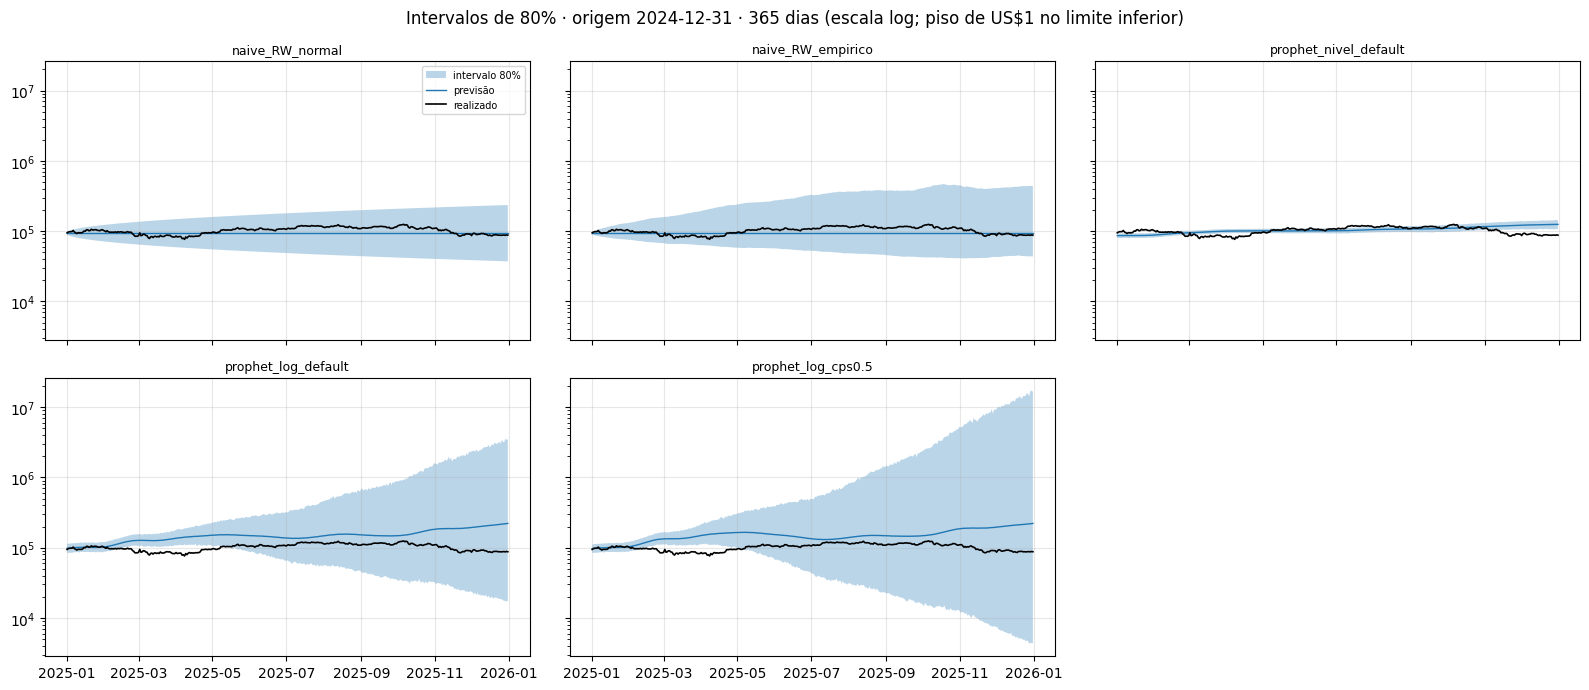

=== INTERVALOS: COBERTURA, LARGURA E INTERVAL SCORE (nominal = coluna 'nível') ===
cobertura = fração dos dias com o preço dentro do intervalo; cob_por_origem±EP usa o nº de origens (acertos dentro da janela são dependentes)
ATENÇÃO: cobertura sem largura não se interpreta. Um intervalo gigante cobre quase tudo sem ser informativo: leia cobertura, razão_hi/lo e interval_score JUNTOS.
ATENÇÃO: os passeios aleatórios também podem não estar calibrados (veja z_cob_vs_nominal); a vantagem deles está no interval_score, não numa calibração perfeita.
           escopo                modelo  nível  cobertura cob_por_origem±EP  z_cob_vs_nominal  largura_log  razão_hi/lo(média geom.)  interval_score_log  %lim_inf<0  min_lim_inf_US$
CV treino (h<=30)       naive_RW_normal    0.8     0.8729       0.873±0.032             2.271       0.3905                     1.478              0.4633           0        1.219e+04
CV treino (h<=30)     naive_RW_empirico    0.8     0.8903       0.890±0.026            

In [28]:
# ===== ETAPA 7 · Parte B: tabelas e gráfico =====
def resumo_int(df):
    linhas = []
    for (esc, mod, nv), g in df.groupby(["escopo", "modelo", "nivel"], sort=False):
        hit = ((g["y"] >= g["lo"]) & (g["y"] <= g["hi"])); a = 1 - nv
        lo_l, hi_l, y_l = [np.log(np.maximum(g[c].values, 1.0)) for c in ("lo", "hi", "y")]     # log com piso de US$1 (só afeta níveis negativos)
        score = (hi_l - lo_l) + (2 / a) * np.maximum(lo_l - y_l, 0) + (2 / a) * np.maximum(y_l - hi_l, 0)
        por_o = hit.groupby(g["t0"]).mean(); n_o = len(por_o)
        linhas.append({"escopo": esc, "modelo": mod, "nível": nv, "cobertura": float(hit.mean()),
                       "cob_por_origem±EP": (f"{por_o.mean():.3f}±{por_o.std(ddof=1) / np.sqrt(n_o):.3f}" if n_o > 1 else "(1 origem)"),
                       "z_cob_vs_nominal": (float((por_o.mean() - nv) / (por_o.std(ddof=1) / np.sqrt(n_o))) if n_o > 1 and por_o.std(ddof=1) > 0 else np.nan),   # NaN se EP=0 (cobertura idêntica em todas as origens)
                       "largura_log": float(np.mean(hi_l - lo_l)), "razão_hi/lo(média geom.)": float(np.exp(np.mean(hi_l - lo_l))),   # cobertura sem largura não se interpreta
                       "interval_score_log": float(np.mean(score)),
                       "%lim_inf<0": float(100 * np.mean(g["lo"].values < 0)), "min_lim_inf_US$": float(g["lo"].min())})
    return pd.DataFrame(linhas)
ri = resumo_int(intv)
ri["modelo"] = pd.Categorical(ri["modelo"], INT_MODELOS, ordered=True); ri["escopo"] = pd.Categorical(ri["escopo"], list(intv["escopo"].unique()), ordered=True)
ri = ri.sort_values(["escopo", "nível", "modelo"]).reset_index(drop=True)

# cobertura por faixa de horizonte (faixas distintas para os escopos de 30 e de 365 dias)
def cob_faixas(df, edges):
    lab = [f"h {a + 1}-{b}" for a, b in zip(edges[:-1], edges[1:])]
    d = df.assign(faixa=pd.cut(df["h"], bins=edges, labels=lab), hit=((df["y"] >= df["lo"]) & (df["y"] <= df["hi"])).astype(float))
    return d.groupby(["escopo", "nivel", "modelo", "faixa"], observed=True)["hit"].mean().unstack("faixa")
edges30, edges365 = [0, 7, 14, CV_HORIZON], [0, CV_HORIZON, 90, H_TEST]
cf30 = cob_faixas(intv[intv["escopo"].isin([e for e in (ESC_CV, ESC_A) if e in set(intv["escopo"])])], edges30)
cfB = cob_faixas(intv[intv["escopo"] == ESC_B], edges365)

# gráfico: faixa de 80% na Parte B (365 dias, uma origem), escala log
b80 = intv[(intv["escopo"] == ESC_B) & (intv["nivel"] == 0.80)]
fig, ax = plt.subplots(2, 3, figsize=(16, 7), sharex=True, sharey=True)
for a, mod in zip(ax.ravel(), INT_MODELOS):
    g = b80[b80["modelo"] == mod]
    a.fill_between(test.index, np.maximum(g["lo"].values, 1.0), g["hi"].values, alpha=.3, label="intervalo 80%")
    a.plot(test.index, g["yhat"].values, lw=1, label="previsão"); a.plot(test.index, g["y"].values, c="k", lw=1.2, label="realizado")
    a.set_yscale("log"); a.set_title(mod, fontsize=9)
ax.ravel()[0].legend(fontsize=7)
for a in ax.ravel()[len(INT_MODELOS):]: a.axis("off")
plt.suptitle(f"Intervalos de 80% · origem {TRAIN_END.date()} · {H_TEST} dias (escala log; piso de US$1 no limite inferior)"); plt.tight_layout(); plt.show()

print("=== INTERVALOS: COBERTURA, LARGURA E INTERVAL SCORE (nominal = coluna 'nível') ===")
print("cobertura = fração dos dias com o preço dentro do intervalo; cob_por_origem±EP usa o nº de origens (acertos dentro da janela são dependentes)")
print("ATENÇÃO: cobertura sem largura não se interpreta. Um intervalo gigante cobre quase tudo sem ser informativo: leia cobertura, razão_hi/lo e interval_score JUNTOS.")
print("ATENÇÃO: os passeios aleatórios também podem não estar calibrados (veja z_cob_vs_nominal); a vantagem deles está no interval_score, não numa calibração perfeita.")
print(ri.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print(f"\n=== COBERTURA POR FAIXA DE HORIZONTE · escopos de {CV_HORIZON} d: faixas {[f'{a + 1}-{b}' for a, b in zip(edges30[:-1], edges30[1:])]} ===")
print(cf30.to_string(float_format=lambda v: f"{v:.3f}"))
print(f"\n=== COBERTURA POR FAIXA DE HORIZONTE · teste B ({H_TEST} d): faixas {[f'{a + 1}-{b}' for a, b in zip(edges365[:-1], edges365[1:])]} ===")
print(cfB.to_string(float_format=lambda v: f"{v:.3f}"))
# ranking por interval score (menor = melhor), lado a lado por escopo e nível
print("\n=== INTERVAL SCORE EM LOG (menor = melhor) ===")
print(ri.pivot_table(index="modelo", columns=["escopo", "nível"], values="interval_score_log", observed=True).to_string(float_format=lambda v: f"{v:.3f}"))

# onde o limite inferior fica negativo (falha 8), com o escopo correto
neg = (intv.assign(neg=intv["lo"] < 0).groupby(["escopo", "modelo", "nivel"], sort=False)
       .agg(dias=("neg", "size"), dias_lim_inf_neg=("neg", "sum"), min_lim_inf_US=("lo", "min")))
neg["%dias"] = 100 * neg["dias_lim_inf_neg"] / neg["dias"]
print("\n=== LIMITE INFERIOR NEGATIVO (US$): escopo × modelo × nível; só linhas com ocorrência ===")
print(neg[neg["dias_lim_inf_neg"] > 0].to_string(float_format=lambda v: f"{v:,.4f}") if (neg["dias_lim_inf_neg"] > 0).any() else "nenhuma ocorrência em nenhum escopo/modelo/nível")
print(f"escopos/níveis/modelos avaliados: {neg.shape[0]} combinações; total de dias com limite inferior negativo: {int(neg['dias_lim_inf_neg'].sum())}")

# hipótese: a volatilidade do treino é maior que a da época avaliada? (desvio-padrão do retorno log diário)
ret_full = np.log(serie_full).diff().dropna()
dp_tr, dp_te = ret_full.loc[:TRAIN_END].std(), ret_full.loc[test.index[0]:].std()
print(f"\n=== DESVIO-PADRÃO DO RETORNO LOG DIÁRIO · treino: {dp_tr:.4f} | teste: {dp_te:.4f} | razão teste/treino: {dp_te / dp_tr:.3f} ===")
print(ret_full.groupby(ret_full.index.year).std().rename("dp_retorno_diario").to_frame().to_string(float_format=lambda v: f"{v:.4f}"))


# Etapa 8: conclusão (falha #9 do tutorial)

*Os números desta conclusão foram lidos da execução com os dados baixados em 2026-10-03T22:51:22 UTC (md5 `e90470b4ee76f9d2e9ffbd3eafebe2a2`, Célula 3). Se uma nova execução mudar o md5, todos os números devem ser reconferidos. A numeração C1, C2, ... e L1, L2, ... serve para auditoria frase por frase e pode ser removida na versão final; os colchetes [Cél. N] indicam a célula de onde vem cada número. As saídas deste arquivo são as da execução acima: as edições posteriores mudaram só textos, rótulos internos e a célula vazia final, e o notebook **não foi reexecutado** depois delas (não o descreva como 'rodado do zero'). **Cinco linhas de saída guardada foram editadas à mão** (1 linha na Célula 25 e 4 na Célula 27), apenas para remover rótulos internos de revisão; nenhum número foi alterado.*

## 8.1 Pergunta e resposta curta

**C1.** Pergunta: o Prophet agrega algo em relação ao naive (benchmark principal; o drift entra só por comparação indireta, ver L9) na previsão do preço diário do BTC-USD quando a avaliação corrige as falhas apontadas na revisão do tutorial de referência (transformação log, benchmarks simples, validação de origem móvel, testes aplicados às séries certas)?

**C2.** Resposta curta: com este desenho, **não encontramos evidência de que o Prophet supere o naive**. Na validação cruzada (CV) ele foi pior com significância estatística; no teste, foi pior em estimativa pontual, mas sem significância após correção para comparações múltiplas (poucas origens). Isso **não prova** que o preço é imprevisível e não exclui que outra especificação, outro horizonte ou outro modelo funcione; diz apenas que não encontramos esse ganho aqui.

## 8.2 Desenho

**C3.** Dados: fechamento diário do BTC-USD (Yahoo Finance), 2017-01-01 a 2025-12-31 (3287 dias, sem faltantes), baixados em 2026-10-03 (UTC). [Cél. 3]

**C4.** Divisão: treino de 2922 dias (até 2024-12-31) e teste de 365 dias (todo 2025), definidos por contagem e sem sobreposição. A análise exploratória, a decomposição e a CV usam só o treino. [Cél. 3]

**C5.** CV de origem móvel (janela expansiva) só dentro do treino: 48 origens, treino inicial de 1460 dias, horizonte de 30 dias, passo de 30 dias; erros em log e MASE em log. [Cél. 19]

**C6.** Teste, em dois formatos que **não se misturam**: **(A)** 12 origens móveis de 30 dias dentro de 2025; **(B)** uma única trajetória de 365 dias a partir de 2024-12-31, que não permite inferência estatística. O teste B é a **mesma trajetória** da Etapa 4: todos os modelos da Etapa 4 estão no teste B, que acrescenta o drift em log e o `cps0.5`. [Cél. 22 e 23]

**C7.** Modelos fixados antes de rodar a Etapa 6: naive, drift em log, drift em nível, naive sazonal de 7 dias, Prophet com defaults em nível, Prophet com defaults em log e o candidato `prophet_log_cps0.5` (escolhido pela regra "menor RMSE em log na CV"). A CV avaliou também `cps0.01`, `flat` e `sem_saz`, para um total de 6 variantes do Prophet. [Cél. 1 e 18]

**C8.** Estatística principal de comparação: Diebold-Mariano com correção de Harvey-Leybourne-Newbold (HLN) sobre o erro² em log, **uma perda por origem**, com correção de Holm nas comparações contra o naive. O erro-padrão HAC entra só como sensibilidade (tende a ser liberal com poucas origens). [Cél. 20]

**C9.** Esta é uma replicação do método em dados atualizados, e **não** uma reprodução dos números do tutorial (a janela é outra), então o RMSE obtido aqui não é comparável ao dele.

## 8.3 Resultados, cada um com o seu escopo

**Exploração (treino, 2922 dias)**

**C10.** No nível, o desvio-padrão cresce com a média (Spearman +0,85 entre blocos de 30 dias); no log isso não ocorre (−0,27). O λ de Box-Cox, por critério próprio inspirado em Guerrero, é 0,115, compatível com a transformação log. [Cél. 10]

**C11.** O log-preço é não estacionário: o ADF não rejeita a raiz unitária (p = 0,37 sem tendência e 0,40 com tendência) e o KPSS rejeita a estacionariedade (p ≤ 0,01 nos dois casos). O retorno é estacionário: ADF p < 1e-16 e KPSS p ≥ 0,10. ADF e KPSS concordam nos dois casos (o ADF tem baixa potência, então "não rejeitar" não prova raiz unitária). [Cél. 10]

**C12.** Os retornos diários têm desvio-padrão de 3,77%, curtose em excesso de 11,3 e 1,40% das observações além de 3 desvios (a normal esperaria 0,27%). [Cél. 10]

**C13.** Autocorrelação linear dos retornos: evidência fraca e inconclusiva (Ljung-Box p = 0,048 no lag 10 e 0,16 no lag 20; Box-Pierce robusto a heterocedasticidade p = 0,33 e 0,63). Há efeito ARCH forte (ARCH-LM p = 1,8e-9 com 5 lags e 2,4e-12 com 10 lags). No GARCH(1,1)-t, α+β = 1,000 (erro-padrão 0,011) e ν = 3,2; nesse regime os p-valores dependentes de momentos finitos valem como evidência **qualitativa**, não como magnitude. [Cél. 10]

**C14.** Sazonalidade: não há evidência de efeito do dia da semana nem do mês na **média** dos retornos (Kruskal-Wallis p = 0,65 e 0,90; Wald com erro HAC p = 0,52 e 0,17). A **magnitude** (|retorno|) difere por dia da semana (p < 1e-16 nos dois testes); o padrão está no gráfico da Célula 9. [Cél. 10]

**Decomposição (MSTL no log-preço do treino)**

**C15.** A sazonalidade não excede o ruído: F_S365 = 0,229 contra mediana de 0,278 no nulo de retornos embaralhados (p da cauda direita = 0,76); F_S7 = 0,0026 contra 0,0053 (p da cauda direita = 0,995; o observado fica até abaixo do nulo, p da cauda esquerda = 0,010). O nulo i.i.d. destrói o agrupamento de volatilidade, o que limita o controle. [Cél. 13]

**C16.** O componente de 365 dias não é um ciclo anual estável: no mesmo dia do calendário (30/mar) ele vai de −0,454 (2017) a +0,403 (2024), em incrementos de 0,11 a 0,14 por ano. A causa mecânica dessa deriva **não foi testada**. [Cél. 13]

**C17.** F_T = 0,961 contra mediana de 0,985 no nulo: o alisador extrai uma "tendência forte" até de um passeio aleatório, então esse valor não prova tendência determinística. [Cél. 13]

**Etapa 4 = teste B: origem única de 365 dias (uma trajetória, sem inferência). C18, C19 e C26 descrevem a mesma trajetória e não são três evidências.**

**C18.** O Prophet em log com defaults previu US$ 97.819 em h = 1 (realizado: US$ 94.420) e US$ 221.231 no último dia (razão final/inicial de 2,26; último preço do treino: US$ 93.429). Seu RMSE foi US$ 56.336 contra US$ 14.326 do naive (3,93×). O Prophet em nível teve RMSE de US$ 15.365 (1,07× o naive) e erro de US$ 8.215 em h = 1, contra US$ 991 do naive. [Cél. 16]

**C19.** O drift em nível teve RMSE de US$ 11.561 (0,81× o naive), enquanto o drift em log teve RMSE em log 1,92× o do naive (extrapola crescimento geométrico: razão final/inicial prevista de 1,76, contra 1,12 do drift em nível). O resultado de um benchmark depende de como o drift é especificado e do regime de 2025. [Cél. 16 e 23]

**CV: 48 origens, horizonte de 30 dias (só treino; erros em log)**

**C20.** RMSE em log relativo ao naive: drift em log 0,98 e drift em nível 0,99 (indistinguíveis do naive: p de Holm = 0,64 e 0,50); naive sazonal 1,15 (pior, p de Holm = 0,008); Prophet em nível 3,11, em log com defaults 2,32 e `cps0.5` 2,10 (Prophet pior que o naive, p de Holm ≤ 2,4e-4 em todas as variantes; para algumas, a autocorrelação de d torna esses p subestimados, mas a conclusão não muda). [Cél. 19 e 20]

**C21.** Na mediana por origem, as variantes do Prophet (exceto `flat`) ficam entre 2,55 e 3,88 vezes o naive, e são melhores que o naive em apenas 6% a 23% das origens. [Cél. 19]

**C22.** Prophet com sazonalidade contra Prophet sem sazonalidade (log): o erro é menor com sazonalidade em 62,5% das origens, mas a diferença não é significativa (p de Holm = 0,12). Isso não é evidência de sazonalidade real: as colunas de Fourier dão flexibilidade extra ao nível. [Cél. 20]

**C23.** O candidato `cps0.5` foi o melhor das 6 variantes. Contra o default na CV: p (HLN) = 0,015, p de Holm = 0,031, melhor em 62,5% das origens. Esse p é **otimista** (viés de seleção, "maldição do vencedor"). No teste A a vantagem **desapareceu**: diferença média (default − candidato) de −0,0022, p = 0,23, melhor em 41,7% das origens, e RMSE relativo ao naive de 2,87 contra 2,81 do default. A seleção não generalizou. [Cél. 20 e 22]

**Teste A: 12 origens de 30 dias dentro de 2025**

**C24.** Estimativa pontual: RMSE em log relativo ao naive de 1,90 (Prophet em nível), 2,81 (log com defaults) e 2,87 (`cps0.5`); o Prophet é melhor que o naive em 25%, 8,3% e 16,7% das origens. Benchmarks: drift em log 1,05, drift em nível 1,00 e naive sazonal 0,97 (melhores que o naive em 50% a 58% das origens). [Cél. 22]

**C25.** Inferência (HLN + Holm, erro²): nenhum Prophet difere significativamente do naive (p de Holm = 0,36, 0,17 e 0,17). Sem correção, p (HLN) = 0,091, 0,034 e 0,028; o HAC dá 0,033, 0,0075 e 0,0056, mas é só sensibilidade e liberal. Com 12 origens o poder é **baixo**: não rejeitar não demonstra equivalência. Os benchmarks não diferem do naive (p de Holm = 1). [Cél. 22]

**Teste B: 365 dias, origem única (sem inferência)**

**C26.** (Mesma trajetória de C18 e C19: os RMSE em US$ coincidem nos modelos comuns às duas etapas, então não é evidência adicional; o teste B acrescenta o drift em log e o `cps0.5`.) RMSE em log: naive 0,141; Prophet em nível 0,150 (1,07×); Prophet em log com defaults 0,432 (3,07×) e `cps0.5` 0,454 (3,23×). Na faixa h = 1 a 30, o Prophet em log parece melhor (0,0385 e 0,0350 contra 0,0776 do naive), mas essa faixa é **a mesma origem e o mesmo modelo da 1ª janela do teste A**, não é evidência independente, e no teste A, com 12 origens, ocorre o oposto. [Cél. 23]

**Resíduos in-sample (ajuste no treino completo)**

**C27.** Os resíduos dos três Prophet têm ρ1 de 0,94 a 0,98, Ljung-Box e ARCH-LM com p < 1e-16; ADF rejeita a raiz unitária e KPSS não rejeita a estacionariedade. Isso significa só "não há raiz unitária no resíduo", esperado por construção com uma tendência flexível; **não** significa ajuste adequado. A ACF no lag 40 é +0,24 (nível), −0,17 e −0,27 (log), então a persistência até o lag 40 vale apenas para o modelo em nível. Como referência, o resíduo do naive (o retorno) tem Ljung-Box p = 0,16 no lag 20 e ARCH-LM p = 2,4e-12. [Cél. 25]

**Intervalos de previsão (nominais de 80% e 95%)**

**C28.** CV (48 origens): o Prophet cobre 0,27 a 0,39 a 80% e 0,44 a 0,61 a 95% (z entre −10,6 e −5,9), ou seja, **subcobertura clara**. Os passeios aleatórios cobrem 0,873 e 0,890 a 80% e 0,983 e 0,990 a 95%, ou seja, acima do nominal: **também não são calibrados**. [Cél. 27]

**C29.** Teste A (12 origens; valor crítico da t(11) a 5% bilateral = 2,20): só o Prophet em nível tem subcobertura clara (cobertura de 0,394 a 80%, z = −3,74; 0,556 a 95%, z = −3,26). As variantes em log ficam dentro do crítico a 80% (cobertura de 0,611 e 0,592; z = −1,41 e −1,56) e marginais a 95% (0,675 e 0,664; z = −2,11 e −2,19). Os passeios aleatórios cobrem de 94% a 99,7%, acima do nominal (não citamos o z deles: com a cobertura encostada em 100%, o erro-padrão vai a ~0 e o z perde sentido). [Cél. 27]

**C30.** Interval score em log (menor é melhor; comparação **descritiva, sem teste de significância**): a 80%, os passeios aleatórios têm 0,46 contra 1,33 a 2,03 do Prophet na CV, e 0,36 a 0,37 contra 0,77 a 1,06 no teste A. A vantagem **não** vem de intervalos mais estreitos: a largura em log a 80% é parecida ou maior (CV: 0,39 nos dois passeios contra 0,29 a 0,39 do Prophet; teste A: 0,35 contra 0,13 a 0,34). Ela vem da penalização por o preço cair fora do intervalo: interval score menos largura = 0,07 (passeio aleatório normal, CV) contra 1,21 (Prophet em log com defaults) e 1,64 (Prophet em nível). O passeio aleatório está centrado no último preço; o Prophet não, e o erro de centro aparece já no horizonte curto: RMSE em log em h 1 a 7 de 0,227 / 0,201 / 0,333 (Prophet em log com defaults, `cps0.5` e em nível) contra 0,0587 do naive na CV, e de 0,184 / 0,185 / 0,124 contra 0,0409 no teste A. [Cél. 19, 22 e 27]

**C31.** Teste B (uma trajetória): o Prophet em log cobre 0,762 (80%) e 0,951 (95%), perto do nominal, mas com razão média entre limite superior e inferior de 7,4 e 62,4 (defaults) e de 21,2 e 608,8 (`cps0.5`): a cobertura "boa" vem de intervalos gigantes, e cobertura sem largura não se interpreta. Nessa mesma trajetória, o Prophet em nível tem o menor interval score dos cinco (0,646 a 80% e 0,920 a 95%), com cobertura de 0,469 e 0,682; é uma só trajetória e não se generaliza. [Cél. 27]

**C32.** Falha 8 do tutorial (limite inferior negativo): reproduzida **apenas** no Prophet em nível, a 95%, na CV: 5 de 1440 dias (0,35%), mínimo de −US$ 792; nunca a 80% e nunca no teste. No ajuste in-sample em nível, 41 de 2922 dias têm valor ajustado ≤ 0 (de 2017-01-01 a 2017-02-10, mínimo de −US$ 2.811). Nos modelos em log, os limites são positivos por construção. [Cél. 25 e 27]

**Volatilidade**

**C33.** O desvio-padrão dos retornos diários é 0,0377 no treino e 0,0219 em 2025 (razão de 0,58), com queda ao longo dos anos (0,049 em 2017, 0,028 em 2024). A **hipótese** de que a cobertura acima do nominal dos passeios aleatórios no teste decorre dessa queda é compatível com esses números, mas **não foi demonstrada**: não há teste que a isole, e os passeios aleatórios também cobrem acima do nominal na CV. [Cél. 27]

## 8.4 Limitações

**L1.** O teste de 2025 foi visto mais de uma vez (Etapas 4, 6 e 7), e a Etapa 7 o usou só como diagnóstico, sem ajuste a partir dele.

**L2.** A lista de variantes do Prophet foi definida **depois** da Etapa 4, que já tinha mostrado o teste (por exemplo, o Prophet em log divergindo). Não é possível garantir que o teste não influenciou o desenho dessa lista.

**L3.** O candidato `cps0.5` está na **borda** da grade de `changepoint_prior_scale` (0,01; 0,05; 0,5), e a grade não foi ampliada (seria uma nova busca). Não afirmamos que **nenhuma** configuração do Prophet supere o naive; afirmamos só que as testadas não superaram neste período e horizonte.

**L4.** Poder baixo no teste A (12 origens de 30 dias, um único ano). O DM com h = 1 supõe diferenciais sem autocorrelação: na CV, a autocorrelação de lag 1 de d é de 0,61 a 0,92 para quatro variantes do Prophet (nível, `cps0.01`, `flat` e `sem_saz`), então os p delas estão subestimados (a conclusão não muda porque são minúsculos). O HAC é só sensibilidade.

**L5.** O teste B é uma trajetória de um único ano e não admite inferência; o desempenho do drift depende do regime e da especificação.

**L6.** Com α+β ≈ 1 e ν ≈ 3,2, os p-valores que dependem de momentos finitos (ARCH-LM, Ljung-Box de r², Box-Pierce robusto) são qualitativos. O ADF e o KPSS em resíduos estimados são aproximados. A amostra cobre regimes distintos (alta de 2017, 2020–21, queda de 2022), então os resultados descrevem este período e não se generalizam.

**L7.** A hipótese de volatilidade (C33) é só uma hipótese. A causa da deriva do componente de 365 dias (C16) também não foi testada. O MSTL é descritivo, com janela anual maior que o número de anos disponíveis.

**L8.** Escopo: um ativo (BTC-USD), fechamento diário do Yahoo, 2017 a 2025, horizontes de 30 e de 365 dias. O Prophet foi usado sem regressores externos nem feriados. Não avaliamos outros ativos, outros horizontes nem outros modelos de previsão.

**L9.** Não há teste Prophet contra drift: a inferência existe só para Prophet contra naive e para cada drift contra o naive. A comparação com o drift é indireta, por RMSE pontual (CV: drift em 0,98 e 0,99 do naive contra 2,10 a 3,11 do Prophet, exceto `flat`, 11,5; teste A: drift em 1,05 e 1,00 contra 1,90 a 2,87). Há inferência entre variantes do Prophet: candidato contra default (C23) e default contra sem sazonalidade (C22).

**L10.** A comparação dos interval scores e das coberturas entre modelos é descritiva, sem teste de significância.

## 8.5 O que esta conclusão afirma e o que não afirma

**C34.** Afirma: nos dados e horizontes testados, o Prophet não superou um benchmark simples (naive); na CV foi pior com significância (48 origens), e no teste foi pior em estimativa pontual, sem significância com 12 origens; seus intervalos de 80% e 95% ficam muito abaixo do nominal na CV, e os que cobrem perto do nominal em 365 dias fazem isso por serem gigantes.

**C35.** Não afirma: que o preço do Bitcoin seja imprevisível, que o Prophet nunca funcione, ou que qualquer modelo permita prever o preço. Nada aqui sustenta uma promessa de previsibilidade; a frase "com certeza obterão melhores estimativas", apontada na revisão do tutorial (o texto original não foi acessado aqui), não encontra apoio nestes resultados.